# Notebook to present the results of the evaluation.

# Helper functions

In [17]:
import os
import json
import numpy as np
import pandas as pd

def load_alternative_results(results_dir):
    """
    Crawls the results directory and loads all alternative hypothesis JSON files 
    into a Pandas DataFrame for Seaborn/Matplotlib plotting.
    """
    records = []
    
    for model_name in os.listdir(results_dir):
        model_path = os.path.join(results_dir, model_name)
        if not os.path.isdir(model_path): continue
        
        # 1. Parse Full Shower Results
        fs_path = os.path.join(model_path, "full_shower_results")
        if os.path.isdir(fs_path):
            records.extend(_extract_alt_metrics(fs_path, model_name, "full_shower"))
            
        # 2. Parse High-Level Features (HLF) Results
        hlf_path = os.path.join(model_path, "hlf_results")
        if os.path.isdir(hlf_path):
            for feature_name in os.listdir(hlf_path):
                feature_path = os.path.join(hlf_path, feature_name)
                if os.path.isdir(feature_path):
                    records.extend(_extract_alt_metrics(feature_path, model_name, feature_name))
                    
    return pd.DataFrame(records)

def _extract_alt_metrics(base_path, model_name, feature_name):
    """Helper function to parse batch directories and JSON files."""
    records = []
    for batch_dir in os.listdir(base_path):
        if not batch_dir.startswith("batch_"): continue
        batch_size = int(batch_dir.split("_")[1])
        
        hyp_dir = os.path.join(base_path, batch_dir, f"alt_hypotheses_{batch_dir}")
        if not os.path.isdir(hyp_dir): continue
        
        for file in os.listdir(hyp_dir):
            if file.endswith(".json"):
                metric_name = file.replace(".json", "")
                file_path = os.path.join(hyp_dir, file)
                
                with open(file_path, "r") as f:
                    data = json.load(f)
                    records.append({
                        "model": model_name,
                        "feature": feature_name,
                        "batch_size": batch_size,
                        "metric": metric_name,
                        # Reconvert the list back to a numpy array for numerical operations
                        "alt_array": np.array(data["alt_array"]),
                        "alt_mean": data["alt_mean"],
                        "alt_std": data["alt_std"],
                        "time": data["time"]
                    })
    return records


def load_all_null_results(null_dir):
    """
    Crawls the Null directory and loads all null hypothesis JSON files 
    into a Pandas DataFrame.
    """
    records = []
    
    # 1. Parse Full Shower Results
    fs_path = os.path.join(null_dir, "full_shower_results")
    if os.path.isdir(fs_path):
        records.extend(_extract_null_metrics(fs_path, "full_shower"))
        
    # 2. Parse High-Level Features (HLF) Results
    hlf_path = os.path.join(null_dir, "hlf_results")
    if os.path.isdir(hlf_path):
        for feature_name in os.listdir(hlf_path):
            feature_path = os.path.join(hlf_path, feature_name)
            if os.path.isdir(feature_path):
                records.extend(_extract_null_metrics(feature_path, feature_name))
                
    return pd.DataFrame(records)

def _extract_null_metrics(base_path, feature_name):
    """Helper function to parse the batch directories for the null results."""
    records = []
    for batch_dir in os.listdir(base_path):
        if not batch_dir.startswith("batch_"): continue
        batch_size = int(batch_dir.split("_")[1])
        
        # Target the specific null hypothesis directory inside the batch folder
        hyp_dir = os.path.join(base_path, batch_dir, f"null_hypotheses_{batch_dir}")
        if not os.path.isdir(hyp_dir): continue
        
        for file in os.listdir(hyp_dir):
            if file.endswith(".json"):
                metric_name = file.replace(".json", "")
                file_path = os.path.join(hyp_dir, file)
                
                with open(file_path, "r") as f:
                    data = json.load(f)
                    
                    # Fallbacks in case the keys were saved as alt_ instead of null_
                    arr = np.array(data.get("null_array", data.get("alt_array", [])))
                    mean = data.get("null_mean", data.get("alt_mean", np.nan))
                    std = data.get("null_std", data.get("alt_std", np.nan))
                    time_val = data.get("time", np.nan)
                    
                    records.append({
                        "feature": feature_name,
                        "batch_size": batch_size,
                        "metric": metric_name,
                        "null_array": arr,
                        "null_mean": mean,
                        "null_std": std,
                        "time": time_val
                    })
    return records


#for full_shower data ndims for each particle is the total number of voxels in the experiment (i.e. ds1: 368/533; ds2:6480; ds3: 40500)
#for feature_ type data (e_inc, layer_e_tot, etc...) ndims is the number of dimensions ndims is the number of layer for that experiment (i.e. ds1: 5/7; ds2:45; ds3: 45)

# Dataset analisys

## Loading alternative (pandas.DataFrame) and Null distributions 

In [18]:
# select result path for null and alternative hypothesis data results 

result_path = '/teo_fs_fast/projects/GENOVA/CaloChallenge/Dataset_1_photons/alternative_hypotheses_modified/' #e_inc corrette
#result_path = '/teo_fs_fast/projects/GENOVA/CaloChallenge/Dataset_1_pions/alternative_hypotheses/'
#result_path = '/teo_fs_fast/projects/GENOVA/CaloChallenge/Dataset_1_pions/alternative_hypotheses_train/' #sul train non su eval
#result_path = '/teo_fs_fast/projects/GENOVA/CaloChallenge/Dataset_2/alternative_hypotheses/'
#result_path = '/teo_fs_fast/projects/GENOVA/CaloChallenge/Dataset_3/alternative_hypotheses/'

alternative_df = load_alternative_results(result_path)
# auto choose the name of the dataset based on the result path
if "Dataset_1_photons" in result_path:
    dataset: str = "1-photon"
    print("Dataset 1-photon selected")
elif "Dataset_1_pions" in result_path:
    dataset: str = "1-pion"
    print("Dataset 1-pion selected")
elif "Dataset_2" in result_path:
    dataset: str = "2"
    print("Dataset 2 selected")
elif "Dataset_3" in result_path:
    dataset: str = "3"
    print("Dataset 3 selected")
else:
    dataset: str = "unknown"
    print("Unknown dataset")


null_path = '/teo_fs_fast/projects/GENOVA/CaloChallenge/Dataset_1_photons/Null/'
#null_path = '/teo_fs_fast/projects/GENOVA/CaloChallenge/Dataset_1_pions/train_null/Null/' #sul train non su eval 
#null_path = '/teo_fs_fast/projects/GENOVA/CaloChallenge/Dataset_2/Null/'
#null_path = '/teo_fs_fast/projects/GENOVA/CaloChallenge/Dataset_3/Null/' 
null_df = load_all_null_results(null_path)

alternative_df["model"].unique()

Dataset 1-photon selected


array(['ds1-photons_11', 'ds1-photons_12', 'ds1-photons_7',
       'ds1-photons_17', 'ds1-photons_25', 'ds1-photons_29',
       'ds1-photons_27', 'ds1-photons_16', 'ds1-photons_28',
       'ds1-photons_1', 'ds1-photons_4', 'ds1-photons_9',
       'ds1-photons_10', 'ds1-photons_26', 'ds1-photons_8'], dtype=object)

### checks for the dataframe

In [19]:
ds1_photons_model_name_map = {
    
    1:  "CaloDiffusion",
    4:  "CaloINN",
    7:  "Calo-VQ",
    8:  "CaloScore",
    9:  "CaloScore (distilled)",
    10: "CaloScore (single-shot)",
    11: "CaloFlow (teacher)",
    12: "CaloFlow (student)",
    16: "CaloMan",
    17: "BoloGAN",
    25: "CaloShower2GAN",
    26: "CaloShower3GAN",
    27: "CaloVAE+INN",
    28: "CaloForest",
    29: "CaloGraph"
}

ds1_pions_model_name_map = {
    
    1:  "CaloDiffusion",
    4:  "CaloINN",
    7:  "Calo-VQ",
    11: "CaloFlow (teacher)",
    12: "CaloFlow (student)",
    16: "CaloMan",
    17: "BoloGAN",
    20: "DNNCaloSim*",
    24: "CaloShowerGAN",
    27: "CaloVAE+INN",
    28: "CaloForest",
    29: "CaloGraph"
}
ds2_model_name_map = {
    
    1:  "CaloDiffusion",
    3:  "conv. L2LFlows",
    4:  "CaloINN",
    5:  "MDMA",
    7:  "Calo-VQ",
    8:  "CaloScore",
    9:  "CaloScore (distilled)",
    10: "CaloScore (single-shot)",
    13: "iCaloFlow (teacher)",
    14: "iCaloFlow (student)",
    15: "SuperCalo",
    22: "DeepTree",
    23: "CaloPointFlow",
    27: "CaloVAE+INN",
    30: "CaloLatent",
    32: "CaloDiT",
    33: "CaloDREAM"
}
ds3_model_name_map = {
    
    1:  "CaloDiffusion",
    2:  "L2LFlows-MAF",
    3:  "conv. L2LFlows",
    5:  "MDMA",
    6:  "CaloClouds",
    7:  "Calo-VQ",
    9:  "CaloScore (distilled)",
    10: "CaloScore (single-shot)",
    13: "iCaloFlow (teacher)",
    14: "iCaloFlow (student)",
    21: "Geant4-Transformer",
    23: "CaloPointFlow",
    27: "CaloVAE+INN",
    31: "Calo-VQ(norm)",
    33: "CaloDREAM"
}

def map_model_name(model_code):
    try:
        idx = int(model_code.split("_")[1])
        set_name = model_code.split("_")[0]
        if set_name == "ds1-photons":
            return ds1_photons_model_name_map.get(idx, model_code)
        elif set_name == "ds1-pions":
            return ds1_pions_model_name_map.get(idx, model_code)
        elif set_name == "ds2":
            return ds2_model_name_map.get(idx, model_code)
        else:
            return ds3_model_name_map.get(idx, model_code)
    except:
        return model_code

alternative_df['model'] = alternative_df['model'].apply(lambda x: map_model_name(x))
#alternative_df.info()
alternative_df["model"].unique()


array(['CaloFlow (teacher)', 'CaloFlow (student)', 'Calo-VQ', 'BoloGAN',
       'CaloShower2GAN', 'CaloGraph', 'CaloVAE+INN', 'CaloMan',
       'CaloForest', 'CaloDiffusion', 'CaloINN', 'CaloScore (distilled)',
       'CaloScore (single-shot)', 'CaloShower3GAN', 'CaloScore'],
      dtype=object)

In [20]:
null_df.info()
null_df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 264 entries, 0 to 263
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   feature     264 non-null    object 
 1   batch_size  264 non-null    int64  
 2   metric      264 non-null    object 
 3   null_array  264 non-null    object 
 4   null_mean   264 non-null    float64
 5   null_std    264 non-null    float64
 6   time        264 non-null    float64
dtypes: float64(3), int64(1), object(3)
memory usage: 14.6+ KB


,feature,batch_size,metric,null_array,null_mean,null_std,time
0,full_shower,20000,SWD,"[254.4887237548828, 317.7508544921875, 250.558...",241.429443,51.871403,43.959665
1,full_shower,20000,KS,"[0.6259787678718567, 0.9005439281463623, 0.780...",0.709089,0.155370,44.822579
2,full_shower,20000,SKS,"[0.9688503742218018, 1.138500452041626, 0.9765...",0.877753,0.141371,35.580595
3,full_shower,20000,MMD,"[0.0024275612086057663, 0.007907424122095108, ...",0.004707,0.001883,89.866525
4,full_shower,100,SWD,"[180.3724822998047, 189.15789794921875, 115.65...",191.979721,67.140564,3.062444


## violin plots

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def prepare_violin_data(df_alt, df_null, feature_name, metric_name):
    """
    Filters the DataFrames and explodes the arrays into long-form format.
    Adds the Null distribution as a baseline 'Model'.
    """
    # 1. Isolate the alternative distributions
    mask_alt = (df_alt['feature'] == feature_name) & (df_alt['metric'] == metric_name)
    df_alt_sub = df_alt[mask_alt][['model', 'batch_size', 'alt_array']].copy()
    
    # Rename array column for consistency and explode (1 row per array element)
    df_alt_sub = df_alt_sub.rename(columns={'alt_array': 'value'})
    df_alt_exploded = df_alt_sub.explode('value')
    
    # 2. Isolate the null distributions
    mask_null = (df_null['feature'] == feature_name) & (df_null['metric'] == metric_name)
    df_null_sub = df_null[mask_null][['batch_size', 'null_array']].copy()
    
    # Add a dummy model name for the null distributions
    df_null_sub['model'] = 'Null (Reference)'
    df_null_sub = df_null_sub.rename(columns={'null_array': 'value'})
    df_null_exploded = df_null_sub.explode('value')
    
    # 3. Combine both into one plotting DataFrame
    plot_df = pd.concat([df_null_exploded, df_alt_exploded], ignore_index=True)
    
    # Ensure values are float (explode sometimes leaves them as objects)
    plot_df['value'] = plot_df['value'].astype(float)
    plot_df['batch_size'] = plot_df['batch_size'].astype(str) # String format looks better in legends
    
    return plot_df

In [22]:


tests: list = ["KS","SKS","SWD"]
for test in tests:
    output_dir: str = "/teo_fs_fast/projects/GENOVA/figures/"+"ds_"+str(dataset)+"_"+test
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
        fname: str= "ds_"+str(dataset)+"_"+test+"_violin"
        
        plt.savefig(output_dir+"/"+fname+".pdf", format= "pdf")

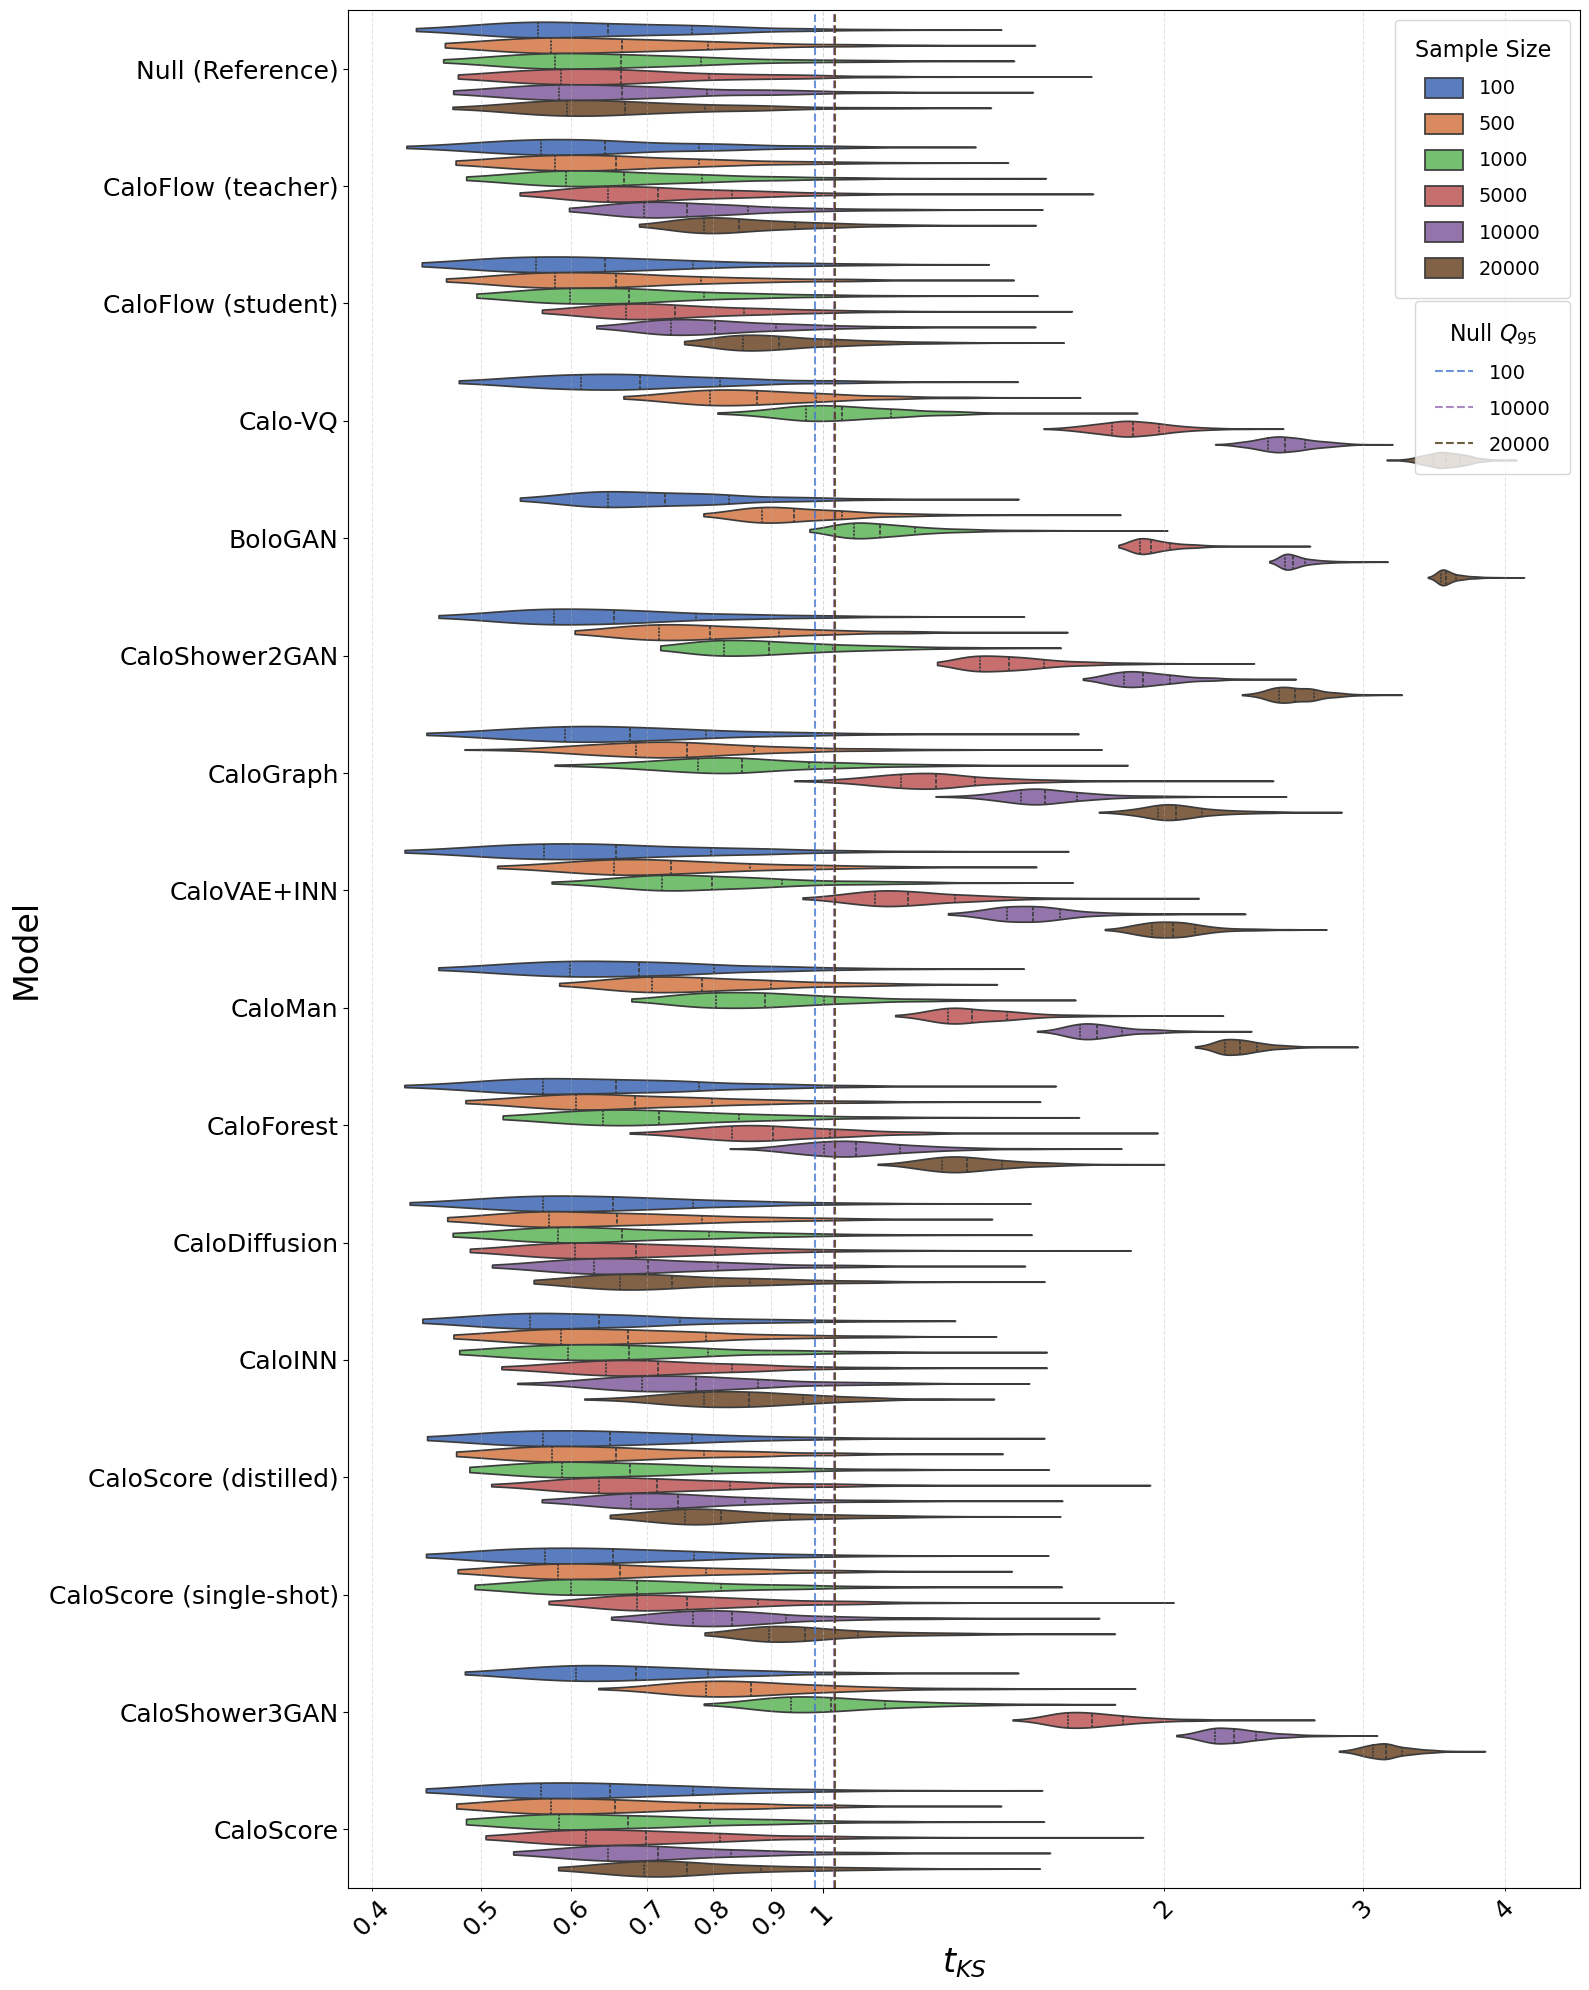

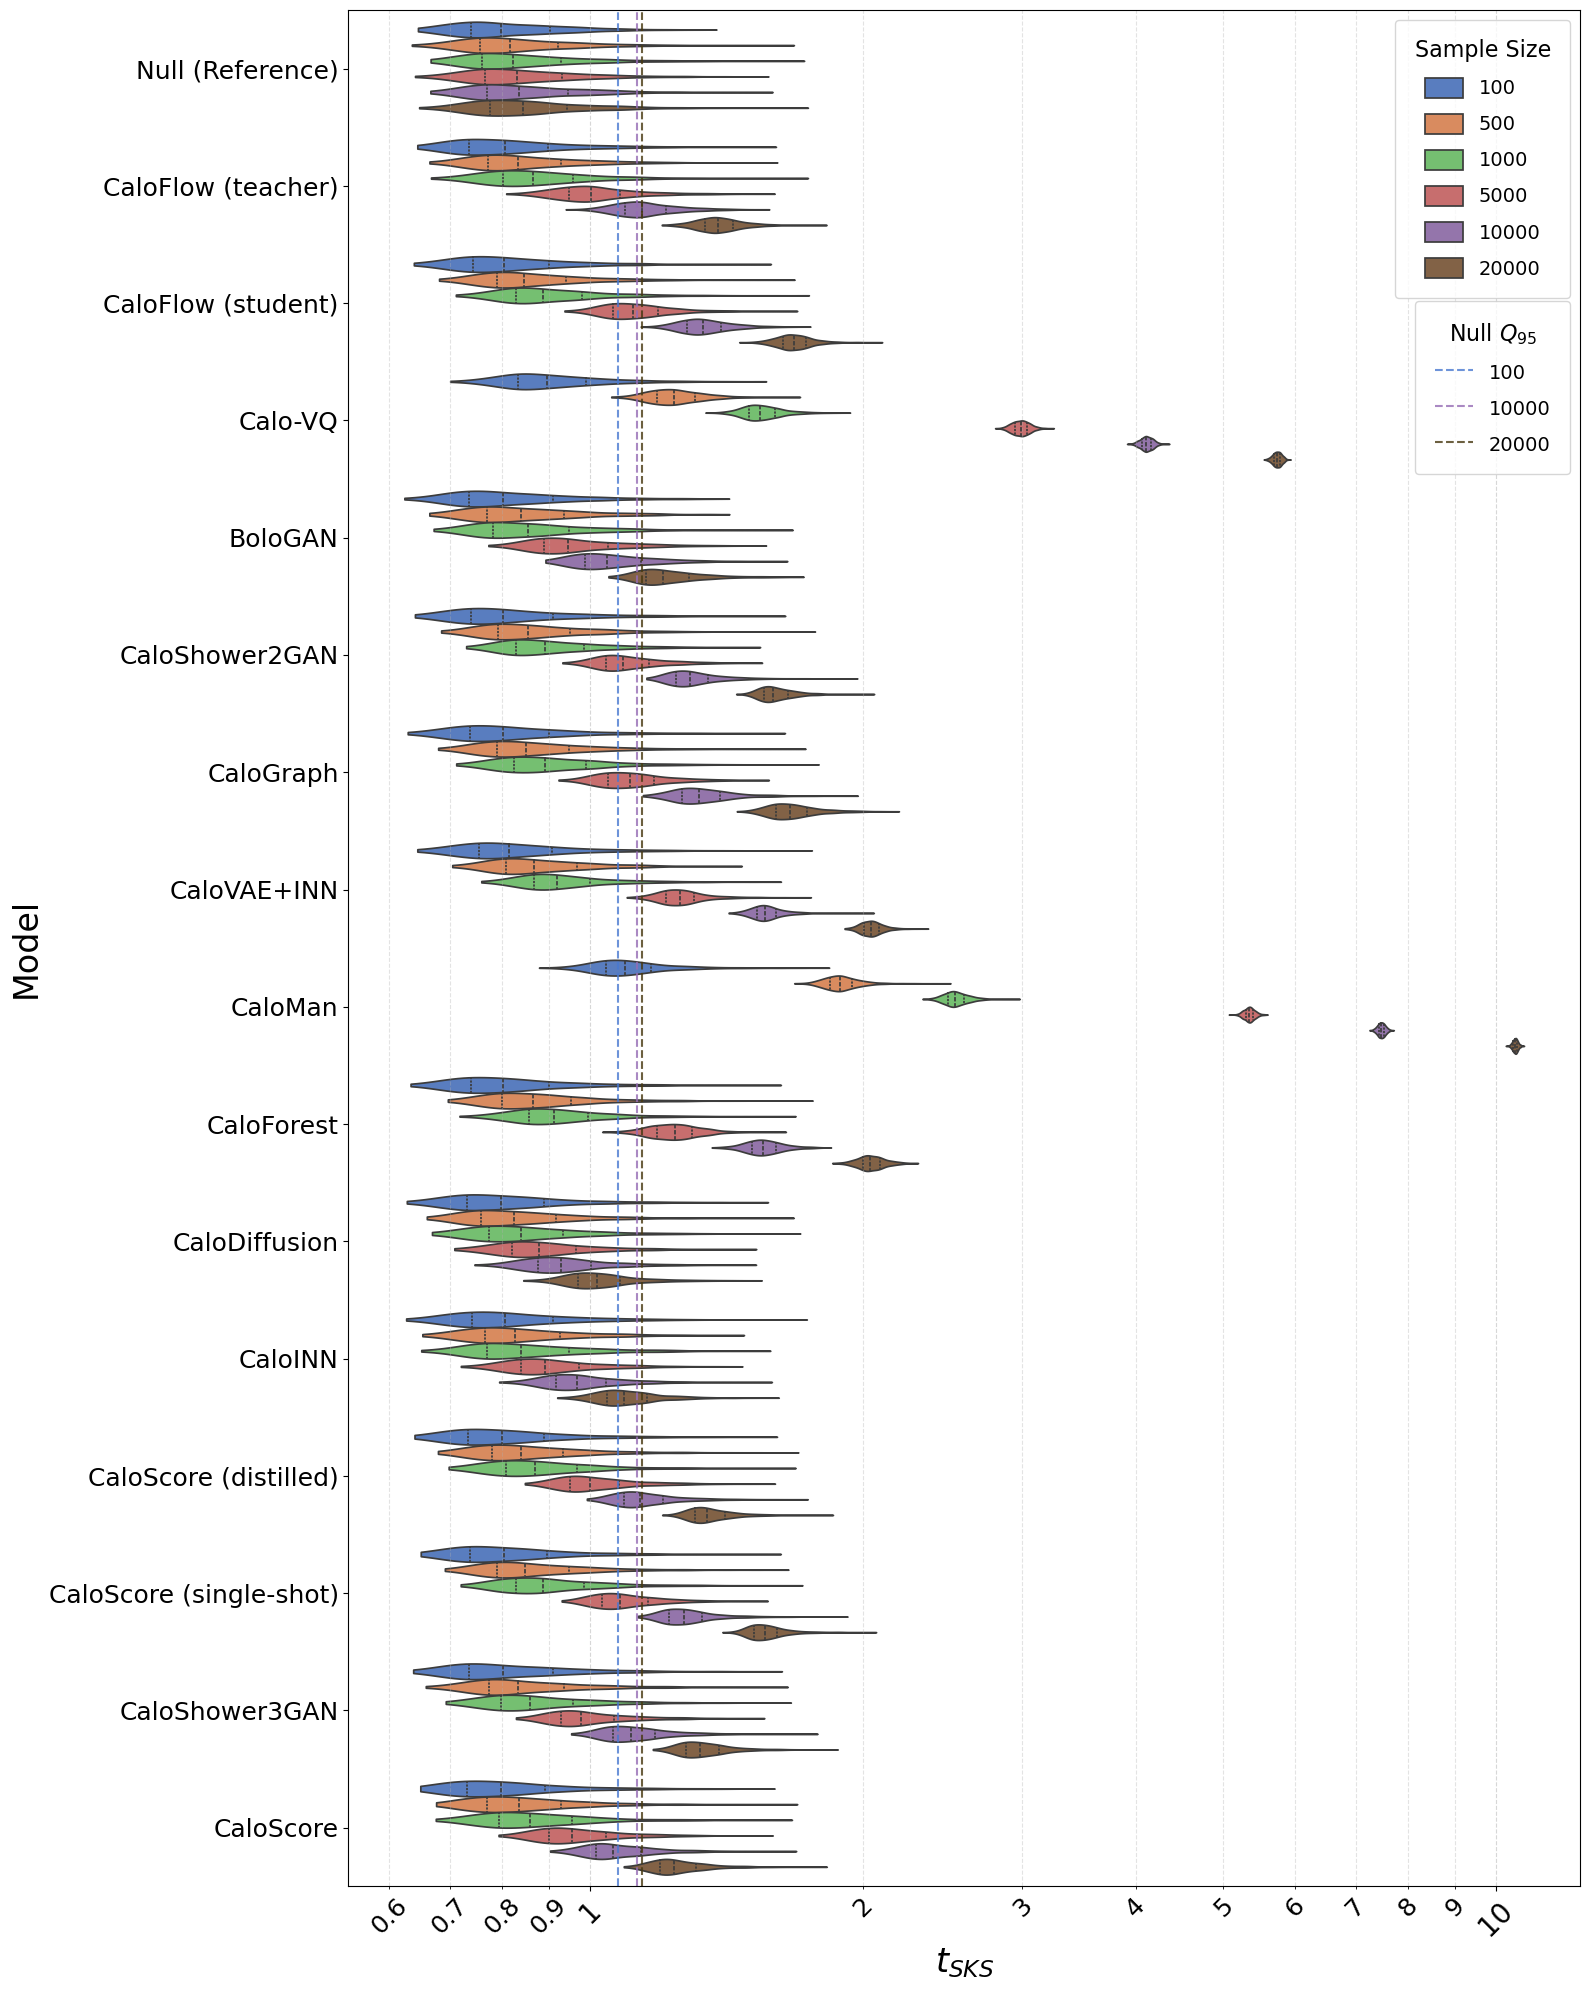

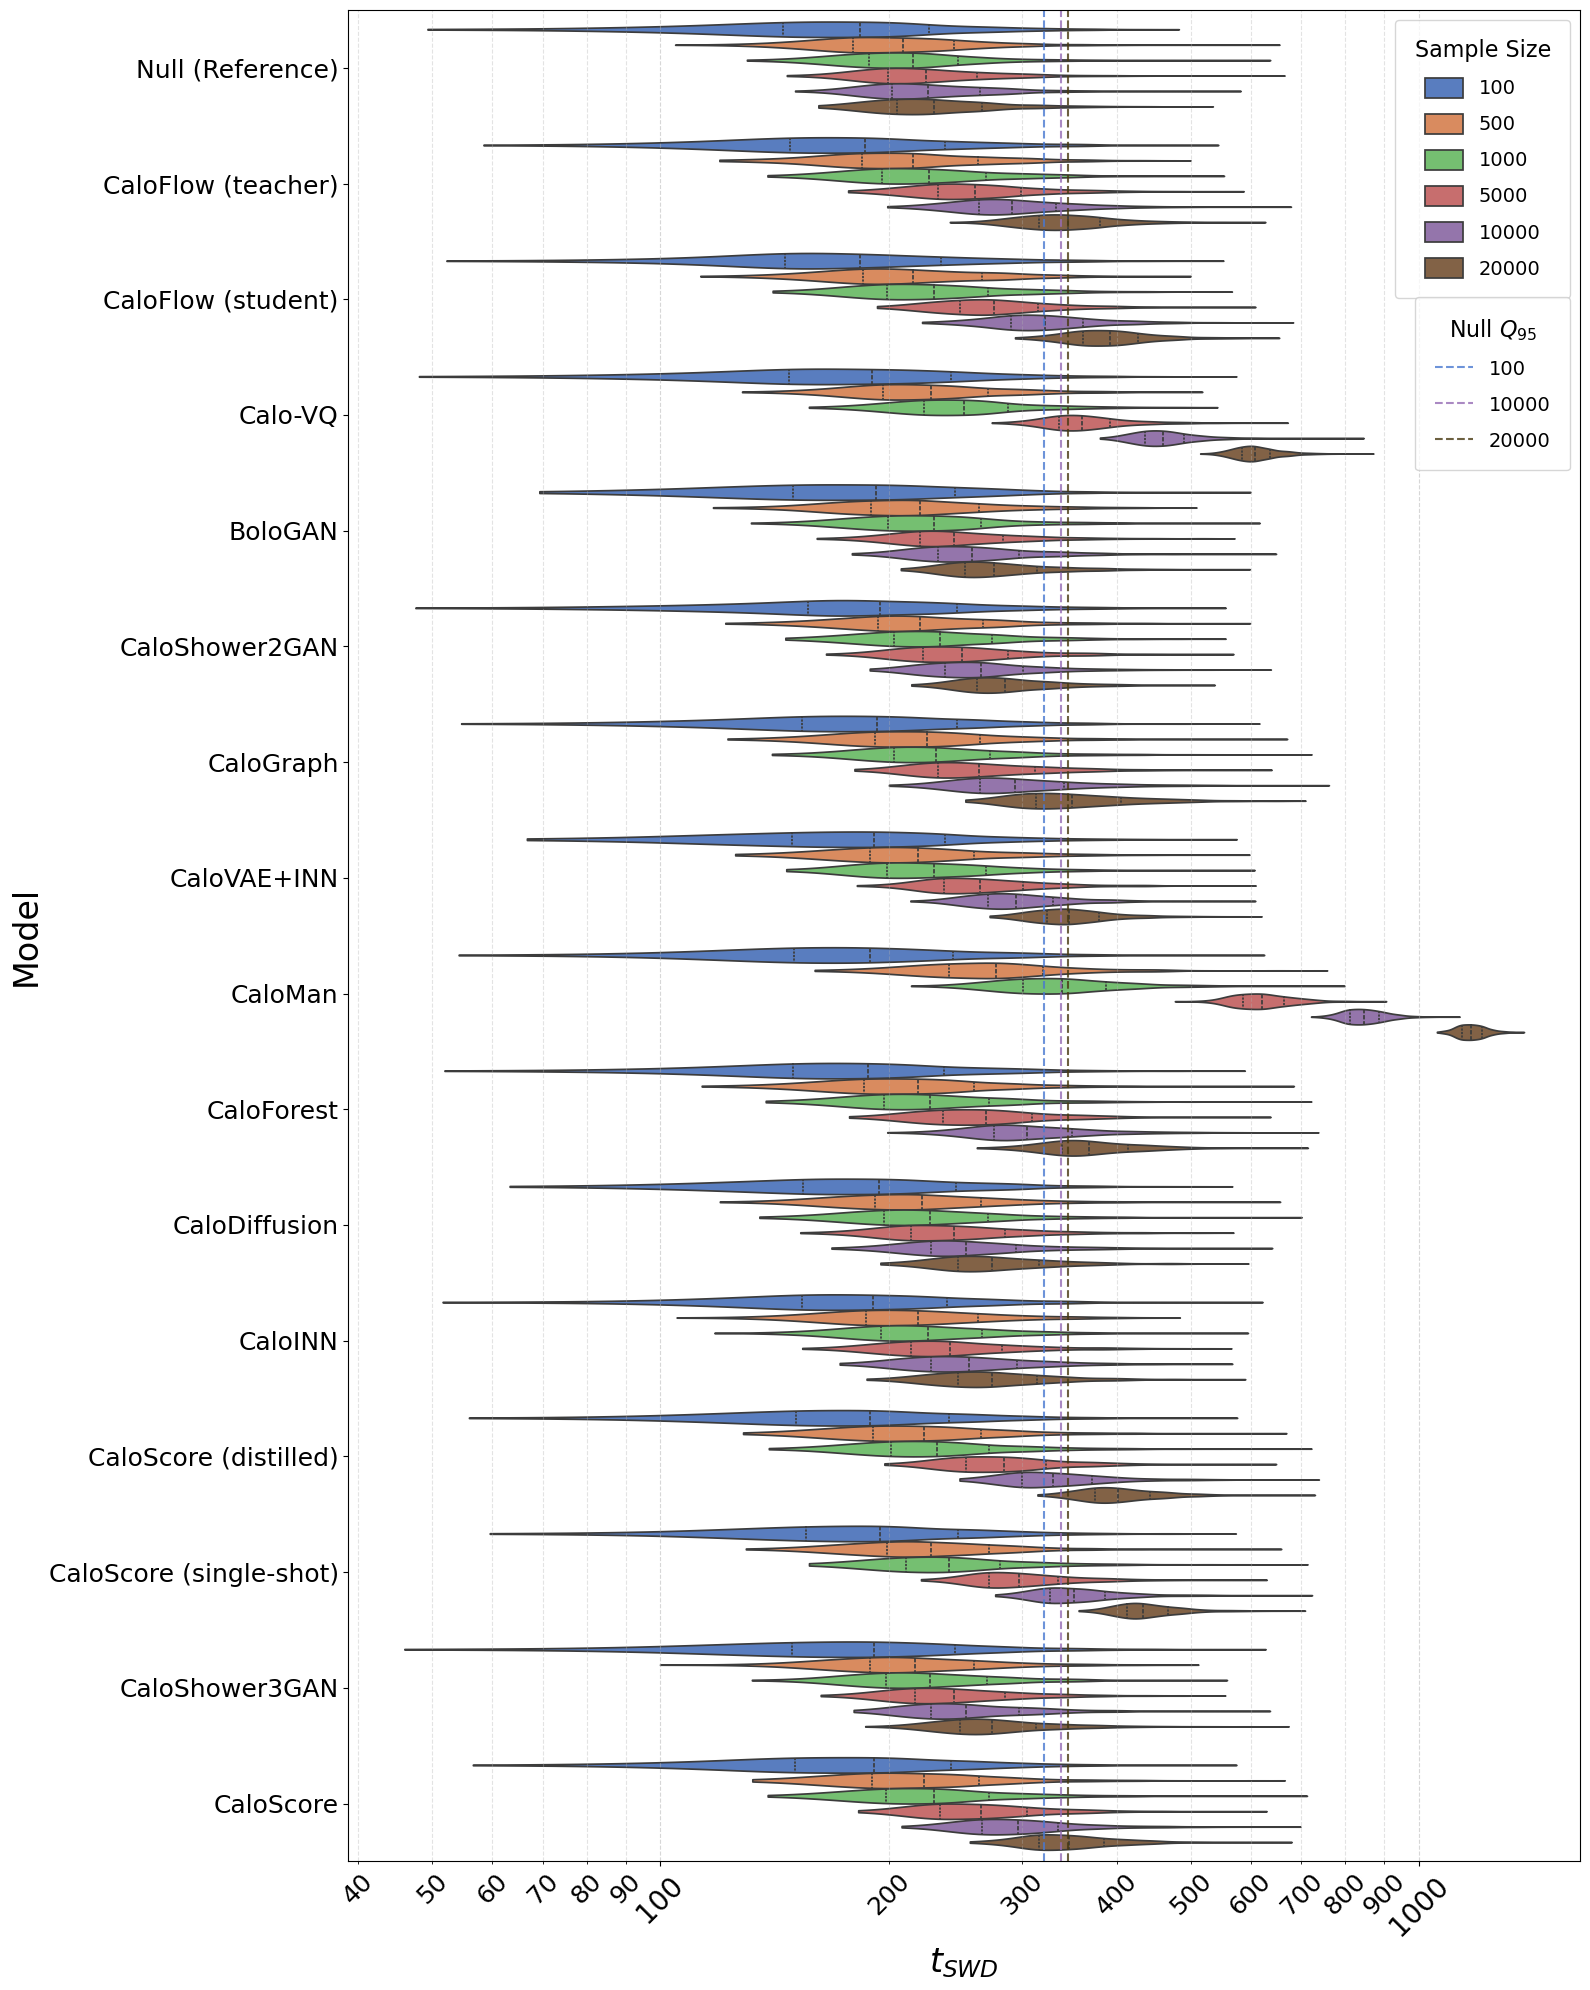

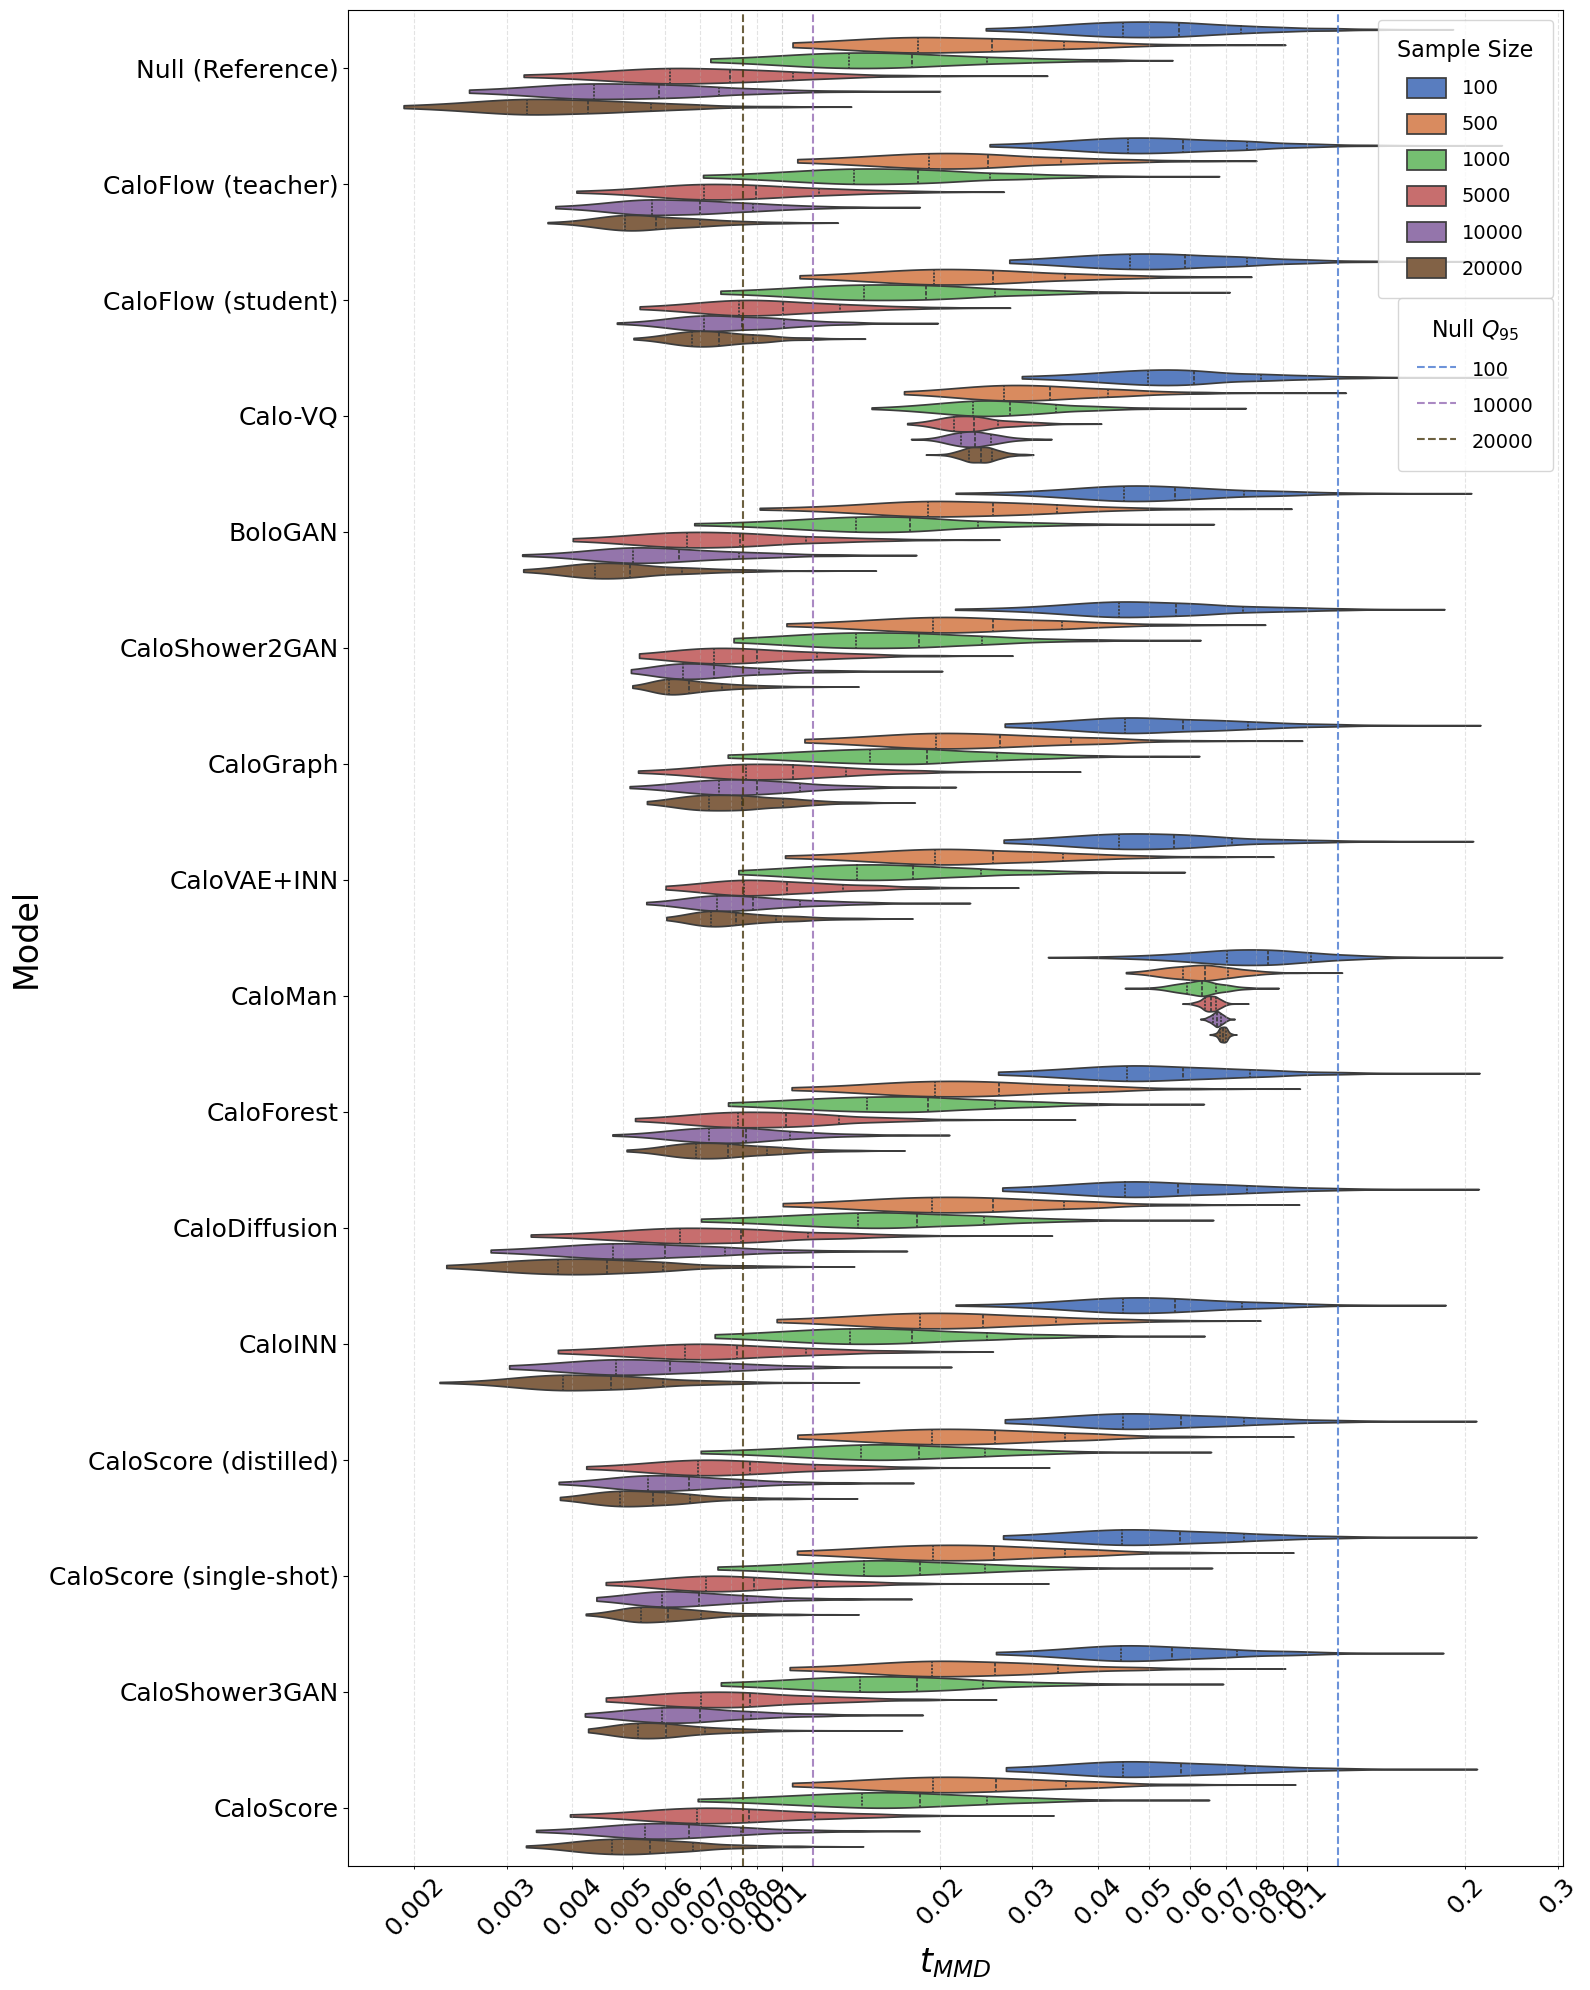

In [23]:
# Select what you want to plot
from matplotlib.ticker import FuncFormatter
import matplotlib.ticker as ticker

FEATURE = 'full_shower'


tests: list = ["KS","SKS","SWD","MMD"]
for test in tests:
    
    # Prepare the data
    plot_df = prepare_violin_data(alternative_df, null_df, FEATURE, test)
    plot_df["batch_size"] = plot_df["batch_size"].astype(int)
    
    
    #prepare line for reference
    q_null_100 = plot_df[
        (plot_df["model"] == "Null (Reference)") &
        (plot_df["batch_size"] == 100)
        ]["value"].quantile(0.95)

    q_null_10000 = plot_df[
        (plot_df["model"] == "Null (Reference)") &
        (plot_df["batch_size"] == 10000)
        ]["value"].quantile(0.95)
    
    q_null_20000 = plot_df[
        (plot_df["model"] == "Null (Reference)") &
        (plot_df["batch_size"] == 20000)
        ]["value"].quantile(0.95)
    
    #prepare directory
    output_dir: str = "/teo_fs_fast/projects/GENOVA/figures/"+"ds_"+str(dataset)+"_"+test
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    fname: str= "ds_"+str(dataset)+"_"+test+"_violin"



    # Initialize a large figure
    plt.figure(figsize=(16, 20))

    # Create the violin plot
    # y='model' puts models on the vertical axis
    # hue='batch_size' draws a different colored violin for each batch size next to the model

    sns.violinplot(
        data=plot_df, 
        x='value', 
        y='model', 
        hue='batch_size', 
        split=False,           # Set to True if you only have exactly 2 batch sizes, otherwise False
        inner='quartile',      # Draws lines inside the violin for 25th, 50th (median), 75th percentiles
        density_norm='width',         # Ensures all violins have the same width regardless of sample size
        palette='muted', 
        cut=0
    )

    plt.xscale("log")
    ax = plt.gca()
    ax.xaxis.set_major_locator(
        ticker.LogLocator(base=10.0, numticks=20))
    ax.xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=np.arange(2, 10), numticks=100))
    
    def log_tick_formatter(x, pos):
        if x >= 1:
            return f"{x:g}"
        else:
            return f"{x:.3g}"

    ax.xaxis.set_major_formatter(FuncFormatter(log_tick_formatter))
    ax.xaxis.set_minor_formatter(FuncFormatter(log_tick_formatter))
    ax.tick_params(axis='x', which='major', labelsize=20, rotation=45)
    ax.tick_params(axis='x', which='minor', labelsize=18, rotation=45)
    ax.grid(which='major', axis='x', linestyle='-', alpha=0.7)
    ax.grid(which='minor', axis='x', linestyle='--', alpha=0.35)
    ax.tick_params(axis='y', labelsize=18)
    
    
    plt.axvline(
        q_null_100,
        color="#4878D0",
        linestyle="--",
        linewidth=1.5,
        alpha=0.8,
        label="100"
    )

    plt.axvline(
        q_null_10000,
        color="#956CB4",
        linestyle="--",
        linewidth=1.5,
        alpha=0.8,
        label="10000"
    )
    
    plt.axvline(
        q_null_20000,
        color="#473810",
        linestyle="--",
        linewidth=1.5,
        alpha=0.8,
        label="20000"
    )
    
    # Move the legend outside the plot area
    #plt.legend(title='Sample Size', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=14, title_fontsize=16)
    handles, labels = ax.get_legend_handles_labels()
    leg1 = ax.legend(
        handles[:6], labels[:6],
        title="Sample Size",
        bbox_to_anchor=(1.0, 1),
        fontsize=14, 
        title_fontsize=16,
        loc="upper right",
        handlelength=2.0,
        handleheight=1.2,
        borderpad=1.0,
        labelspacing=0.8
    )

    # mantieni la prima legenda
    ax.add_artist(leg1)

    # seconda legenda
    ax.legend(
        handles[6:], labels[6:],
        title="Null $Q_{{95}}$",
        bbox_to_anchor=(1.0, 0.85),
        fontsize=14,
        title_fontsize=16,
        loc="upper right",
        handlelength=2.0,
        handleheight=1.2,
        borderpad=1.0,
        labelspacing=0.8
    )

    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.xlabel(f"$t_{{{test}}}$", size=24)
    plt.ylabel("Model", size=24)

    # Adjust layout to fit the legend
    plt.tight_layout()
    plt.savefig(output_dir+"/"+fname+".pdf", format= "pdf")
    plt.show()
    
    

## Generate P-value table

In [24]:


FEATURE = 'full_shower'





def get_p_null(dataframe, z, batch_size):
    null_values = dataframe[
        (dataframe["model"] == "Null (Reference)") &
        (dataframe["batch_size"] == batch_size)
    ]["value"]
    return (null_values >= z).mean()
                        
def get_median(dataframe, model_name,batch_size):
    return dataframe[
        (dataframe["model"] == model_name) &
        (dataframe["batch_size"] == batch_size)
        ]["value"].median()
   
   
def p_table(plot_df, test):
    rows = []

    for model in plot_df["model"].unique():
        if model == "Null (Reference)":
            continue

        for batch_size in plot_df["batch_size"].unique():
            median_value = get_median(plot_df, model, batch_size)
            p_null = get_p_null(plot_df, median_value, batch_size)

            rows.append({
                "Model": model,
                "Batch Size": batch_size,
                "P-null": p_null
            })

    df = pd.DataFrame(rows)

    table = df.pivot(
        index="Model",
        columns="Batch Size",
        values="P-null"
    )

    formatted_table = table.copy().astype(object)

    for col in table.columns:
        max_value = table[col].max()

        def format_pvalue(x):

            # Resolution limit
            if x < 1e-3:
                value = r"$<10^{-3}$"
            else:
                value = f"{x:.3f}"

            # Bold maximum of the column
            if x == max_value:
                value = rf"\textbf{{{value}}}"

            return value

        formatted_table[col] = table[col].apply(format_pvalue)
    #save to latex file 
    tex_file_path: str = "/teo_fs_fast/projects/GENOVA/figures/"+"ds_"+str(dataset)+ "_" + test + "_" + "table.tex"
    with open(tex_file_path, "w", encoding="utf-8") as f:
        f.write(
            formatted_table.to_latex(
                escape=False,
                na_rep="-",
                caption=(
                    r"Empirical $p_{\mathrm{null}}$ values for each generative model "
                    r"at different batch sizes. The highest value for each batch size "
                    r"is highlighted in bold."
                ),
                label="tab:p_null",
                position="htbp"
        )
    
    )

    return table


In [25]:


tests: list = ["KS","SKS","SWD","MMD"]
for test in tests:
    # Prepare the data
    plot_df = prepare_violin_data(alternative_df, null_df, FEATURE, test)
    plot_df["batch_size"] = plot_df["batch_size"].astype(int)
    p_table(plot_df, test)

## violin test

In [26]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def prepare_split_violin_data(df_alt, df_null, feature_name, metric_name):
    # 1. Prepare Alternative Data
    mask_alt = (df_alt['feature'] == feature_name) & (df_alt['metric'] == metric_name)
    df_alt_sub = df_alt[mask_alt][['model', 'batch_size', 'alt_array']].copy()
    df_alt_sub = df_alt_sub.rename(columns={'alt_array': 'value'})
    df_alt_exploded = df_alt_sub.explode('value')
    df_alt_exploded['dist_type'] = 'Alternative'
    
    # 2. Prepare Null Data
    mask_null = (df_null['feature'] == feature_name) & (df_null['metric'] == metric_name)
    df_null_sub = df_null[mask_null][['batch_size', 'null_array']].copy()
    df_null_sub = df_null_sub.rename(columns={'null_array': 'value'})
    df_null_exploded = df_null_sub.explode('value')
    df_null_exploded['dist_type'] = 'Null'
    
    # 3. Duplicate Null for each model to allow row-by-row comparison
    models = df_alt_sub['model'].unique()
    null_rows = []
    for model in models:
        temp = df_null_exploded.copy()
        temp['model'] = model
        null_rows.append(temp)
    df_null_expanded = pd.concat(null_rows, ignore_index=True)
    
    # 4. Combine and create Y-axis labels
    plot_df = pd.concat([df_null_expanded, df_alt_exploded], ignore_index=True)
    plot_df['value'] = plot_df['value'].astype(float)
    plot_df['model_batch'] = plot_df['model'] + ' (Batch ' + plot_df['batch_size'].astype(str) + ')'
    
    # Sort to keep models and their batches grouped together
    plot_df = plot_df.sort_values(by=['model', 'batch_size'])
    
    return plot_df

## 2ND VIOLIN PLOT ##

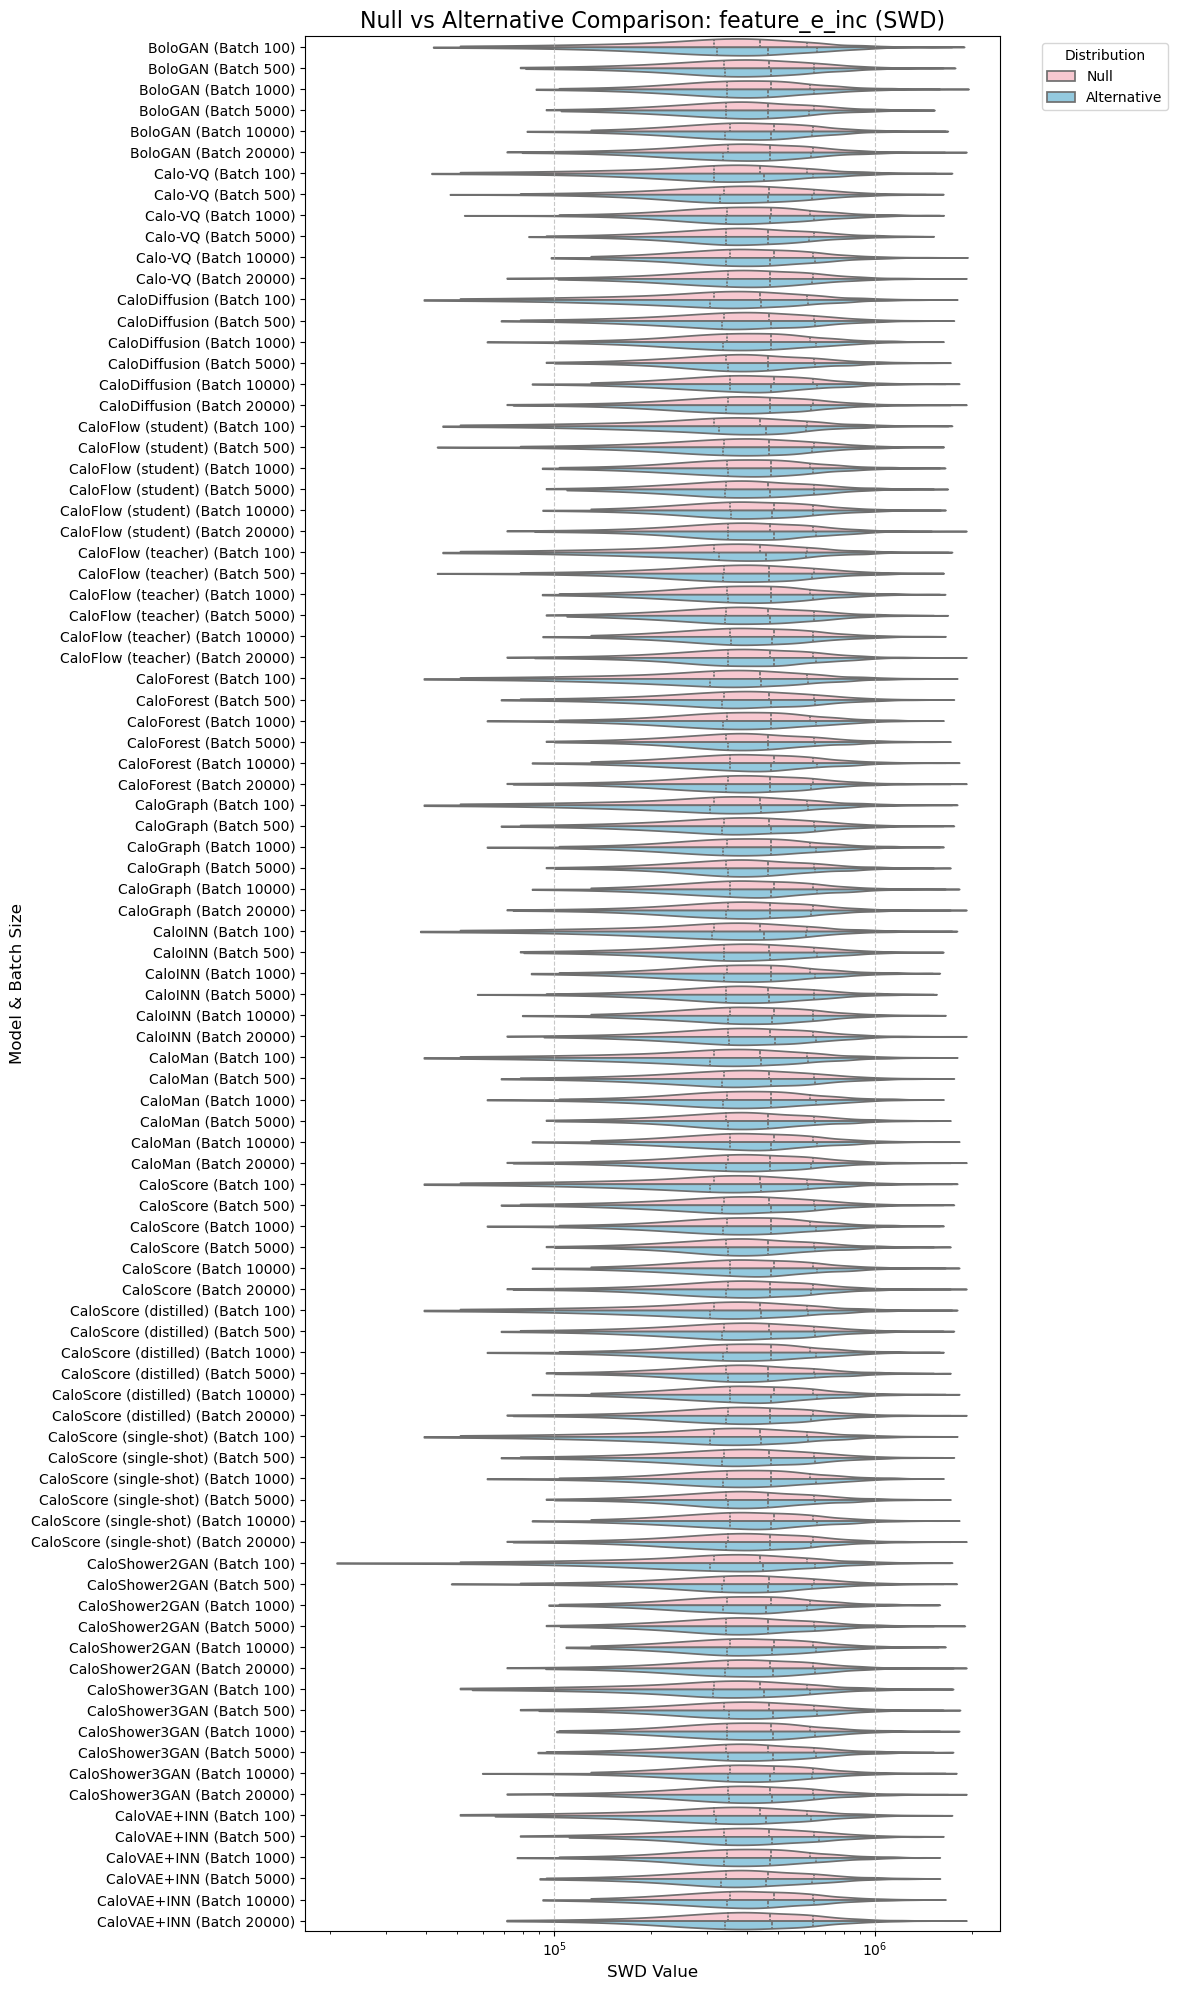

In [27]:
# Select what you want to plot
FEATURE = 'feature_e_inc' 
METRIC = 'SWD'

# Prepare the data
plot_df = prepare_split_violin_data(alternative_df, null_df, FEATURE, METRIC)

# Initialize a large figure (height increased to accommodate more Y-axis labels)
plt.figure(figsize=(12, 20))

# Create the split violin plot
sns.violinplot(
    data=plot_df, 
    x='value', 
    y='model_batch',      # Y-axis is now Model + Batch Size
    hue='dist_type',      # Hue is now Null vs Alternative
    split=True,           # Splits the violin perfectly in half
    inner='quartile', 
    density_norm='width',
    palette={'Null': 'pink', 'Alternative': 'skyblue'}, # Distinct colors for clarity
    cut=0                 # Prevents smoothing past actual min/max values
)
plt.xscale('log')
plt.title(f"Null vs Alternative Comparison: {FEATURE} ({METRIC})", fontsize=16)
plt.xlabel(f"{METRIC} Value", fontsize=12)
plt.ylabel("Model & Batch Size", fontsize=12)

# Optional: Log scale if one model (like ds2_32) is stretching the plot
# plt.xscale('log')

plt.legend(title='Distribution', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Text(0.5, 0, 'Log10(SKS Value)')

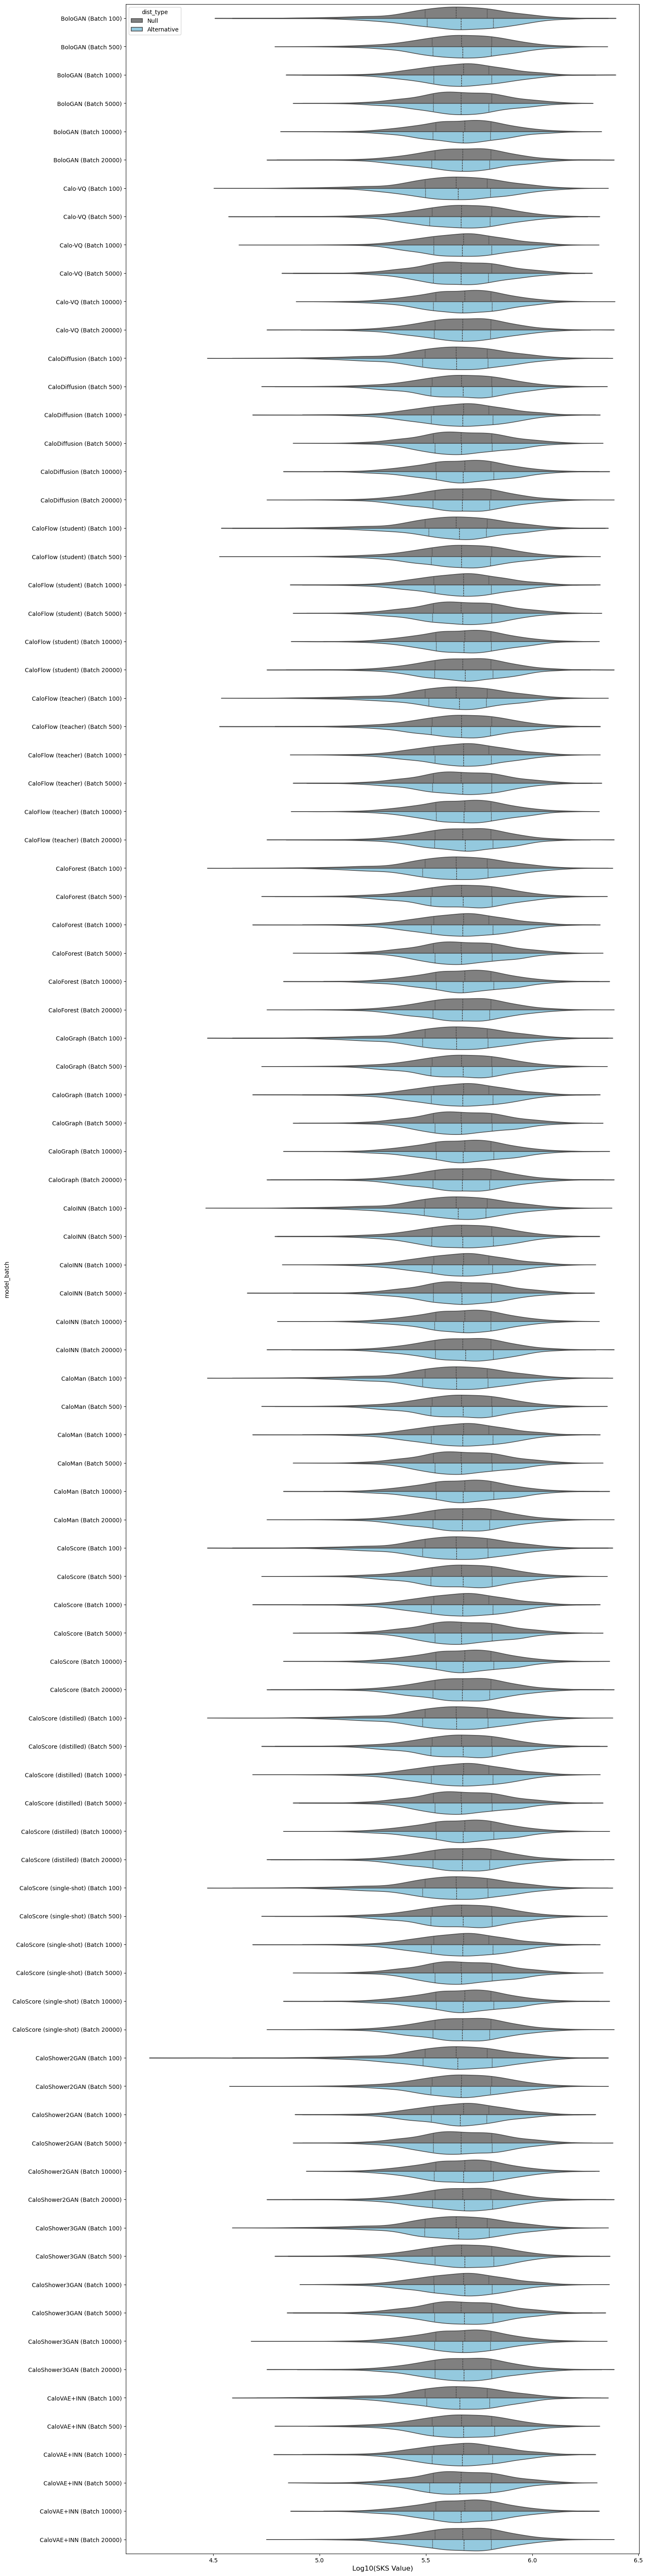

In [28]:
import numpy as np

plt.figure(figsize=(16, 80))
# Add a tiny epsilon (1e-9) to avoid log(0) in case any distance is exactly zero
plot_df['value_log'] = np.log10(plot_df['value'] + 1e-9)

# Plot the log values WITHOUT cut=0
sns.violinplot(
    data=plot_df, 
    x='value_log', 
    y='model_batch',      
    hue='dist_type',      
    split=True,           
    inner='quartile', 
    density_norm='width',
    palette={'Null': 'gray', 'Alternative': 'skyblue'}
)
plt.xlabel("Log10(SKS Value)", fontsize=12)

## Statistical power

In [29]:
label_map = {
    "full_shower": r"$\mathrm{full\ shower}$",
    "feature_width_etas": r"$\sigma_{\eta}$",
    "feature_e_tot": r"$E_{\mathrm{tot}}$",
    "feature_width_phis": r"$\sigma_{\phi}$",
    "feature_sparsity": r"$\mathrm{sparsity}$",
    "feature_ec_phis": r"$EC_{{\phi}}$",
    "feature_e_inc": r"$E_{\mathrm{inc}}$",
    "feature_e_layers": r"$E_{\mathrm{layers}}$",
    "feature_ec_etas": r"$EC_{{\eta}}$",
    "feature_width_r": r"$\sigma_r$",
    "feature_ec_r": r"$EC_{r}$",
}


#remap feature order but with the new labels

feature_order = [
    'feature_e_tot',
    'feature_width_etas',
    'feature_width_phis',
    'feature_ec_phis',
    'feature_e_inc',
    'feature_e_layers',
    'feature_ec_etas',
    'feature_width_r',
    'feature_ec_r',
    'feature_sparsity',
    'full_shower']

# now use scientific notation instead 

feature_order_labels = [label_map.get(f, f) for f in feature_order]


In [30]:
import numpy as np
import pandas as pd

def compute_power_dataframe(df_alt, df_null, alpha=0.05):
    """
    Computes the statistical power for each model, feature, metric, and batch size.
    """
    records = []
    
    # Group the alternative dataframe to isolate each specific test
    for (model, feature, metric, batch_size), group in df_alt.groupby(['model', 'feature', 'metric', 'batch_size']):
        if feature == "feature_e_inc" :#or feature == "full_shower" or feature == "feature_e_tot":
            continue

        
        # Retrieve the matching null distribution
        null_mask = (df_null['feature'] == feature) & (df_null['metric'] == metric) & (df_null['batch_size'] == batch_size)
        null_dist_series = df_null[null_mask]['null_array']
        
        if null_dist_series.empty:
            continue
            
        null_dist = null_dist_series.values[0]
        alt_dist = group['alt_array'].values[0] 
        
        # 1. Define the critical threshold from the baseline (Null)
        critical_value = np.percentile(null_dist, 100 * (1 - alpha))
        
        # 2. Calculate the fraction of the alternative distribution exceeding the threshold
        power = np.mean(alt_dist > critical_value)
        pretty_feature = label_map[feature]
        records.append({
            'model': model,
            'feature': pretty_feature,
            'metric': metric,
            'batch_size': batch_size,
            'power': power
        })
        
    return pd.DataFrame(records)

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_power_heatmap(power_df, target_metric, target_batch_size):
    """
    Pivots the power dataframe and plots a heatmap for a specific metric and batch size.
    """
    # Filter for the specific view
    df_filtered = power_df[(power_df['metric'] == target_metric) & (power_df['batch_size'] == target_batch_size)]
    
    if df_filtered.empty:
        print("No data found for the specified parameters.")
        return
        
    # Pivot to create a 2D matrix: Models on Y, Features on X
    pivot_table = df_filtered.pivot(index='model', columns='feature', values='power')

    feature_order = [
    'feature_e_tot',
    'feature_e_layers',
    'feature_width_etas',
    'feature_width_phis',
    'feature_width_r',
    'feature_ec_etas',
    'feature_ec_phis',
    'feature_ec_r',
    'feature_sparsity',
    'full_shower']

    # now use scientific notation instead
    feature_order = [label_map.get(f, f) for f in feature_order]

    pivot_table = pivot_table.reindex(columns=feature_order)
    
    cmap = sns.color_palette("light:b", as_cmap=True)
    plt.figure(figsize=(16, 8))
    ax = sns.heatmap(
        pivot_table, 
        annot=True,         # Display the power values inside the cells
        #cmap="YlGnBu",      # Yellow (good/low power) to Blue (bad/high power)
        cmap=cmap,         
        vmin=0.05,          # Hard lower bound based on alpha
        vmax=1.0,           # Hard upper bound
        fmt=".2f",          # 2 decimal places
        linewidths=0.5,      # Add gridlines between cells
        cbar=False
    )
    
    #ax.collections[0].colorbar.set_label(
    #'Statistical Power (Rejection Rate)',
    #fontsize=15)

    dataset_map = {
        "1-pion": "Pions",
        "1-photon": "Photons",
        "2": "Dataset 2 electrons",
        "3": "Dataset 3 electrons"
    }

    dataset_name = dataset_map.get(dataset, dataset)
    
    plt.title(
    rf"$\bf{{Rejection\ rate}}$   Metric:{target_metric} "
    f" sample size:{target_batch_size}   Dataset:{dataset_name}",
    fontsize=22
    )


    plt.xlabel("Features", fontsize=20)
    plt.ylabel("Models", fontsize=20)
    plt.xticks(rotation=45, ha='right')
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    
    plt.tight_layout()
    #plt.show()

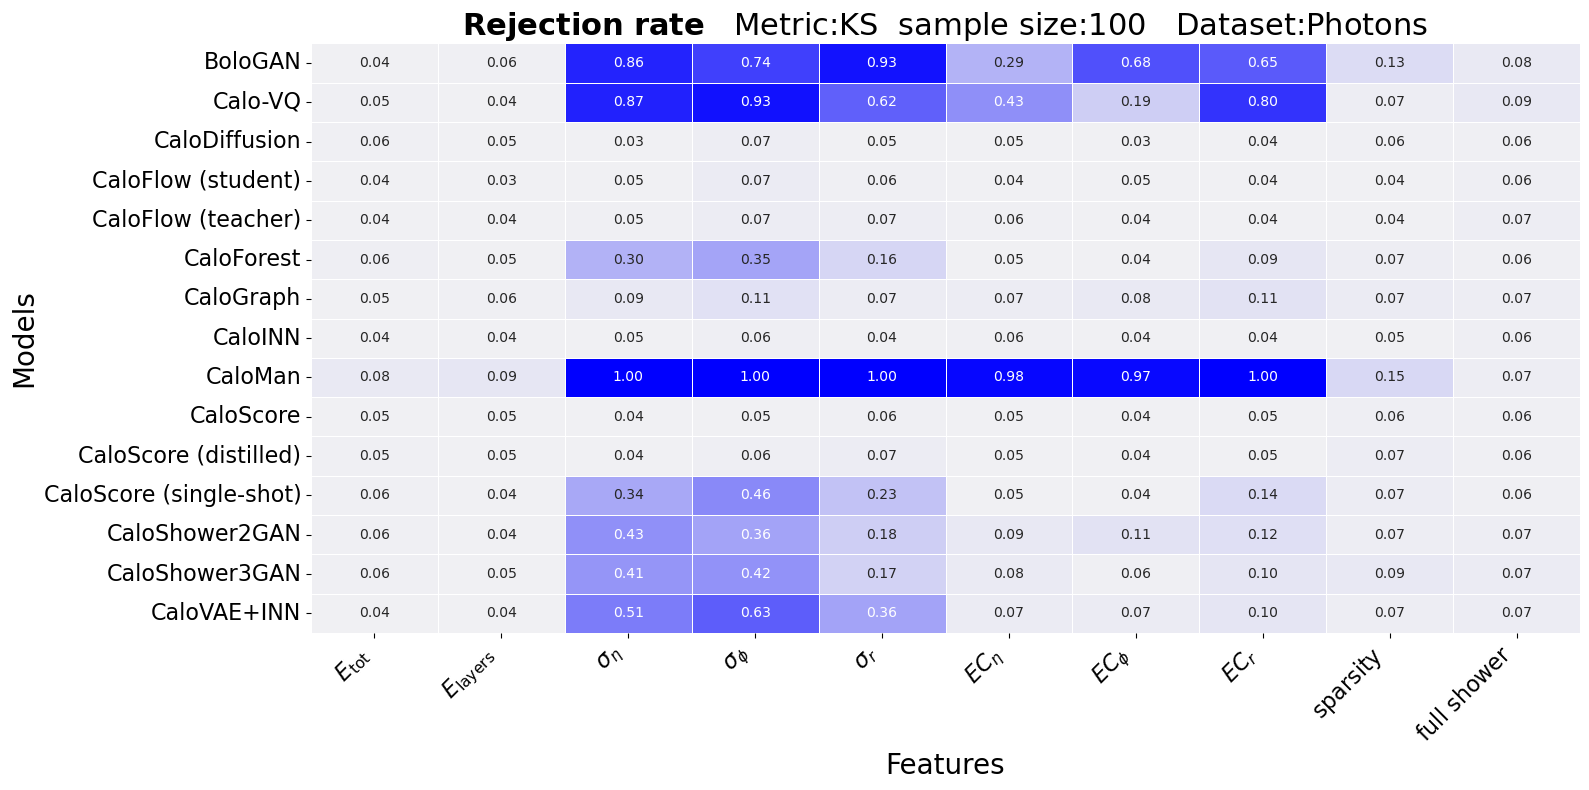

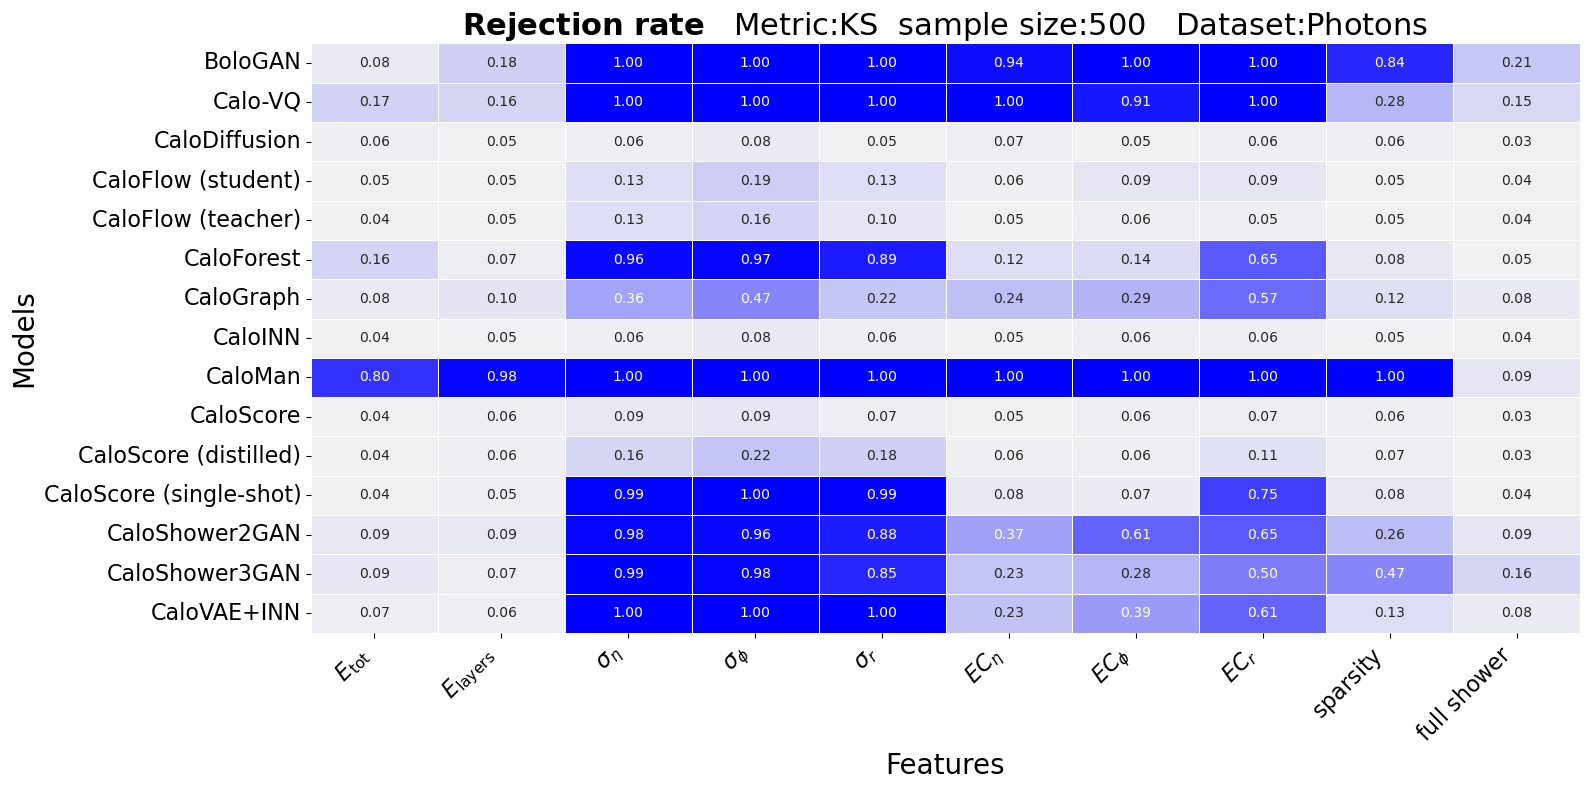

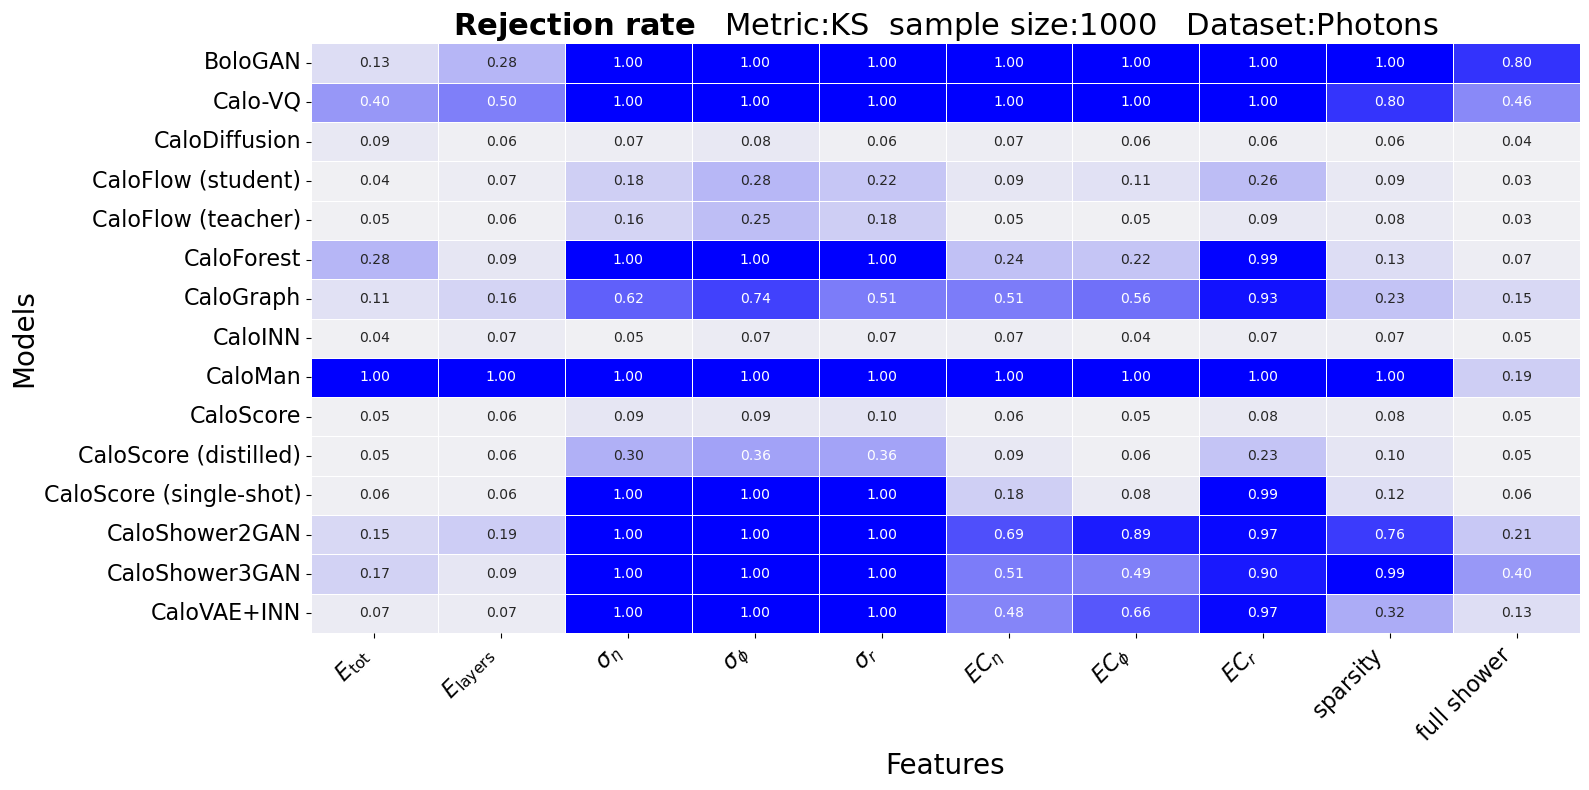

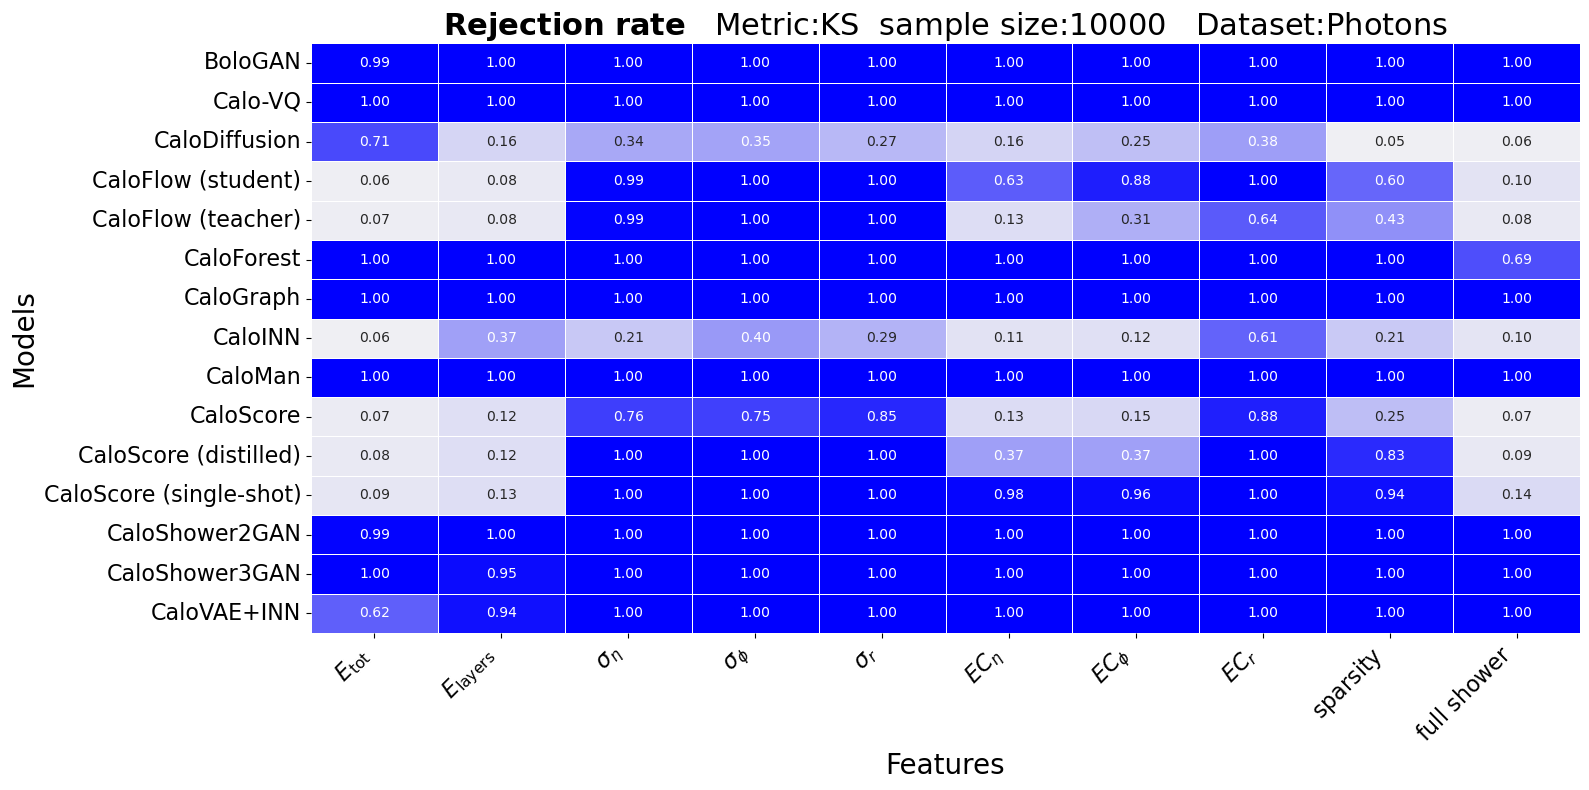

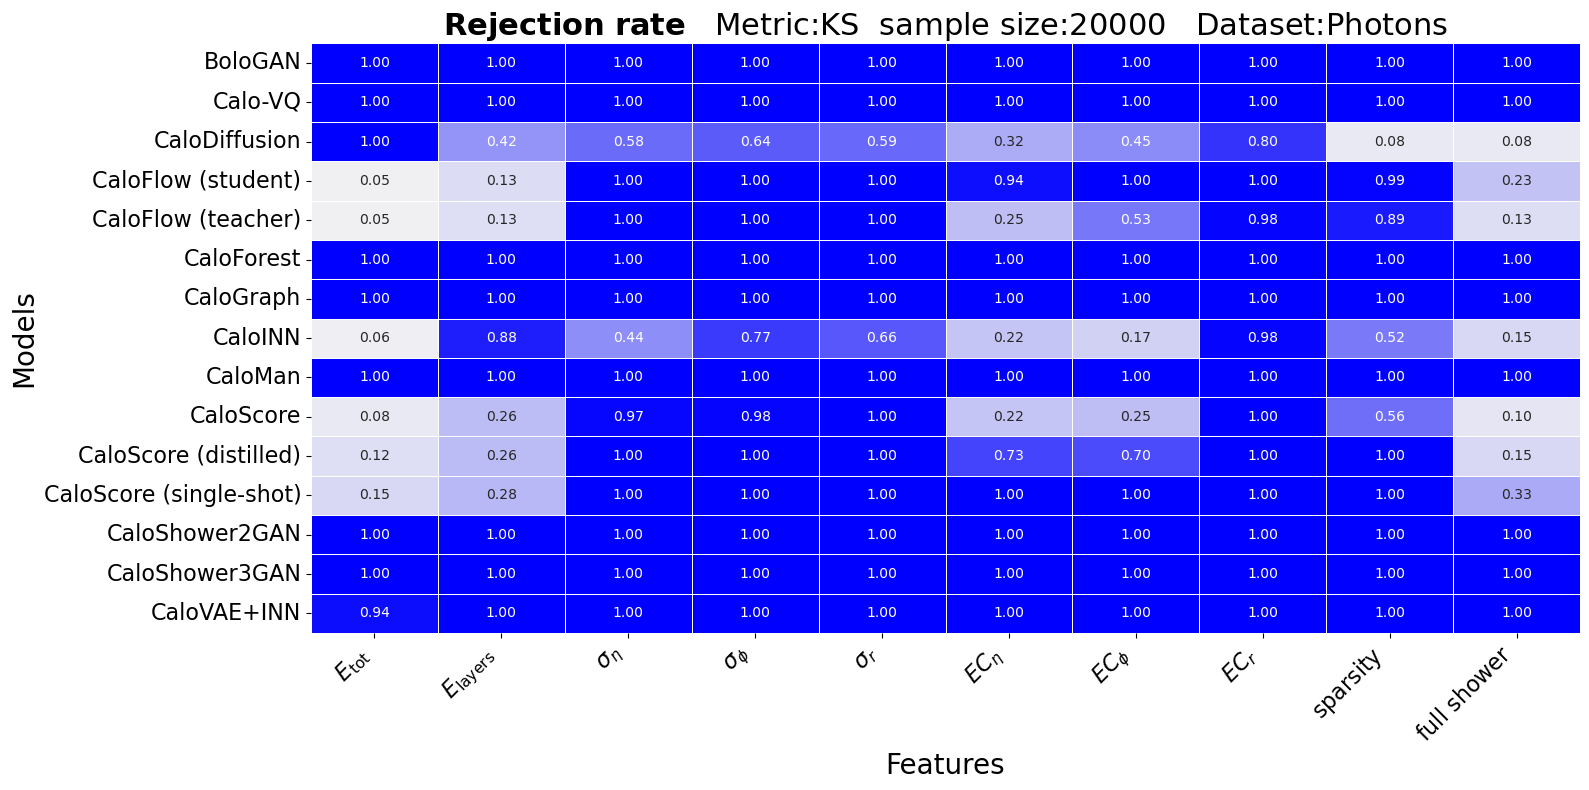

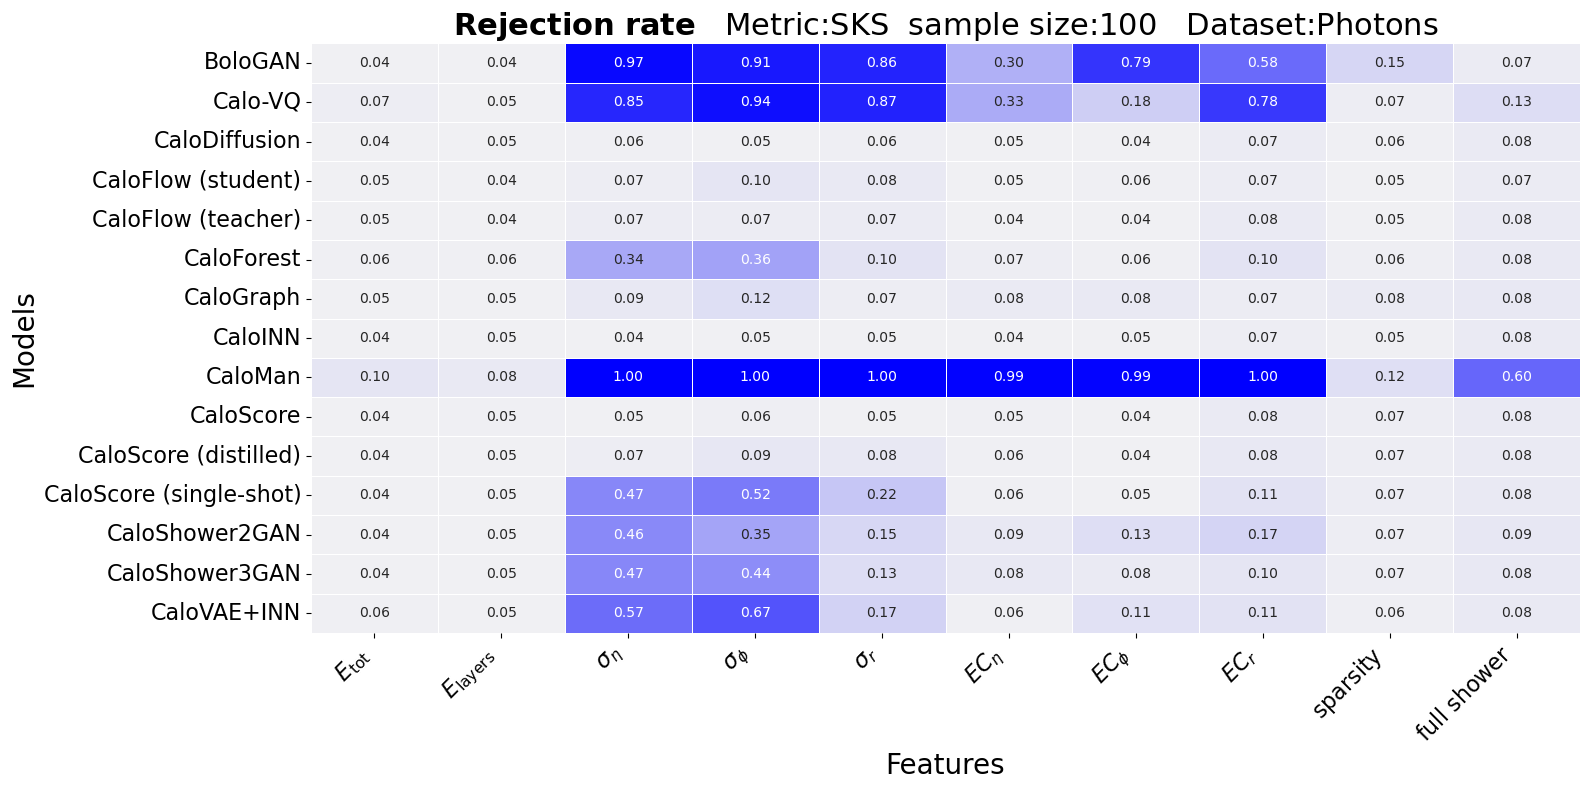

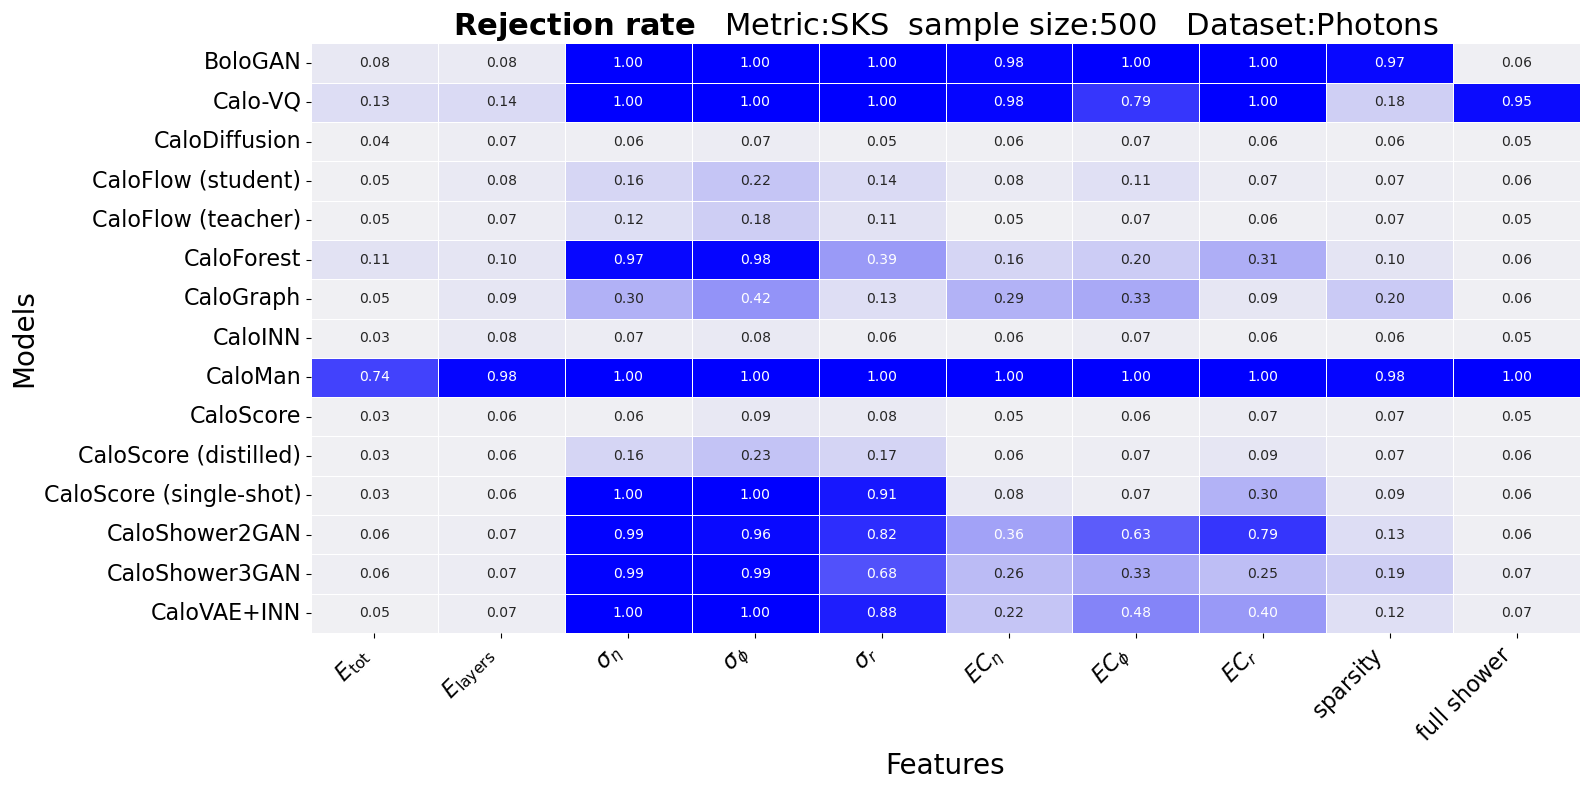

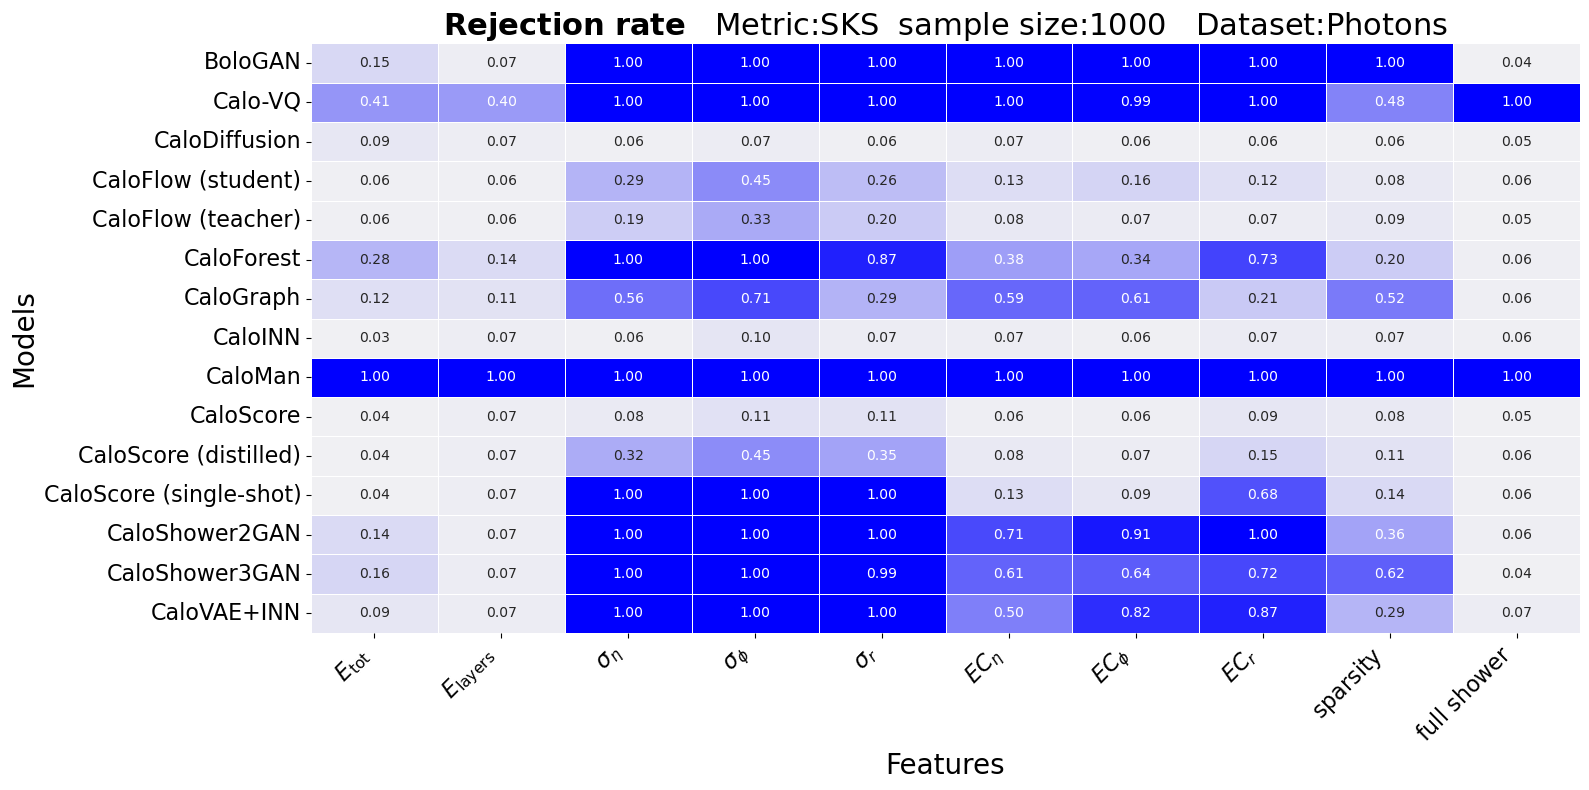

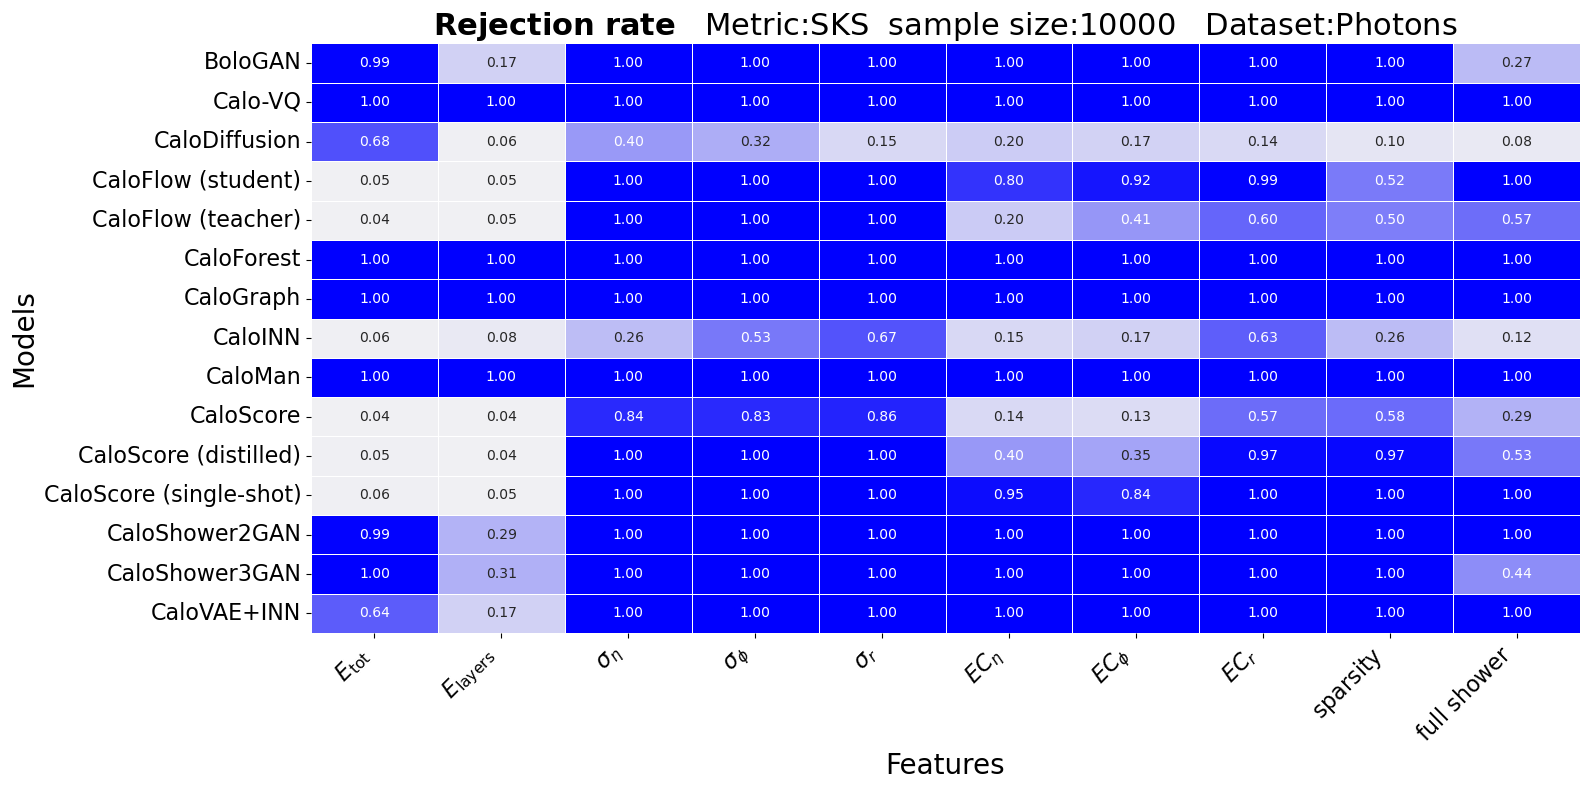

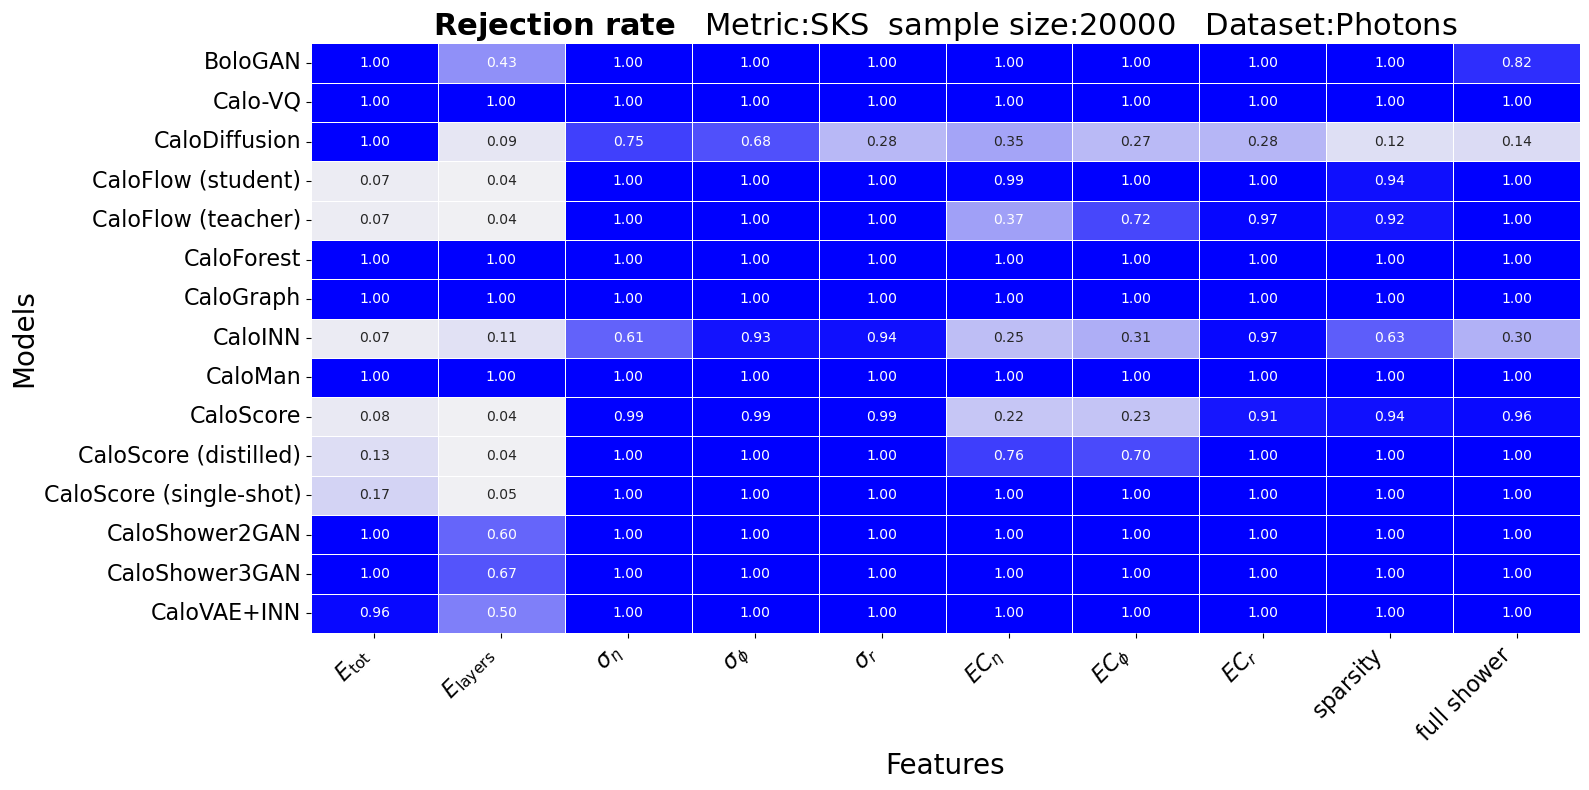

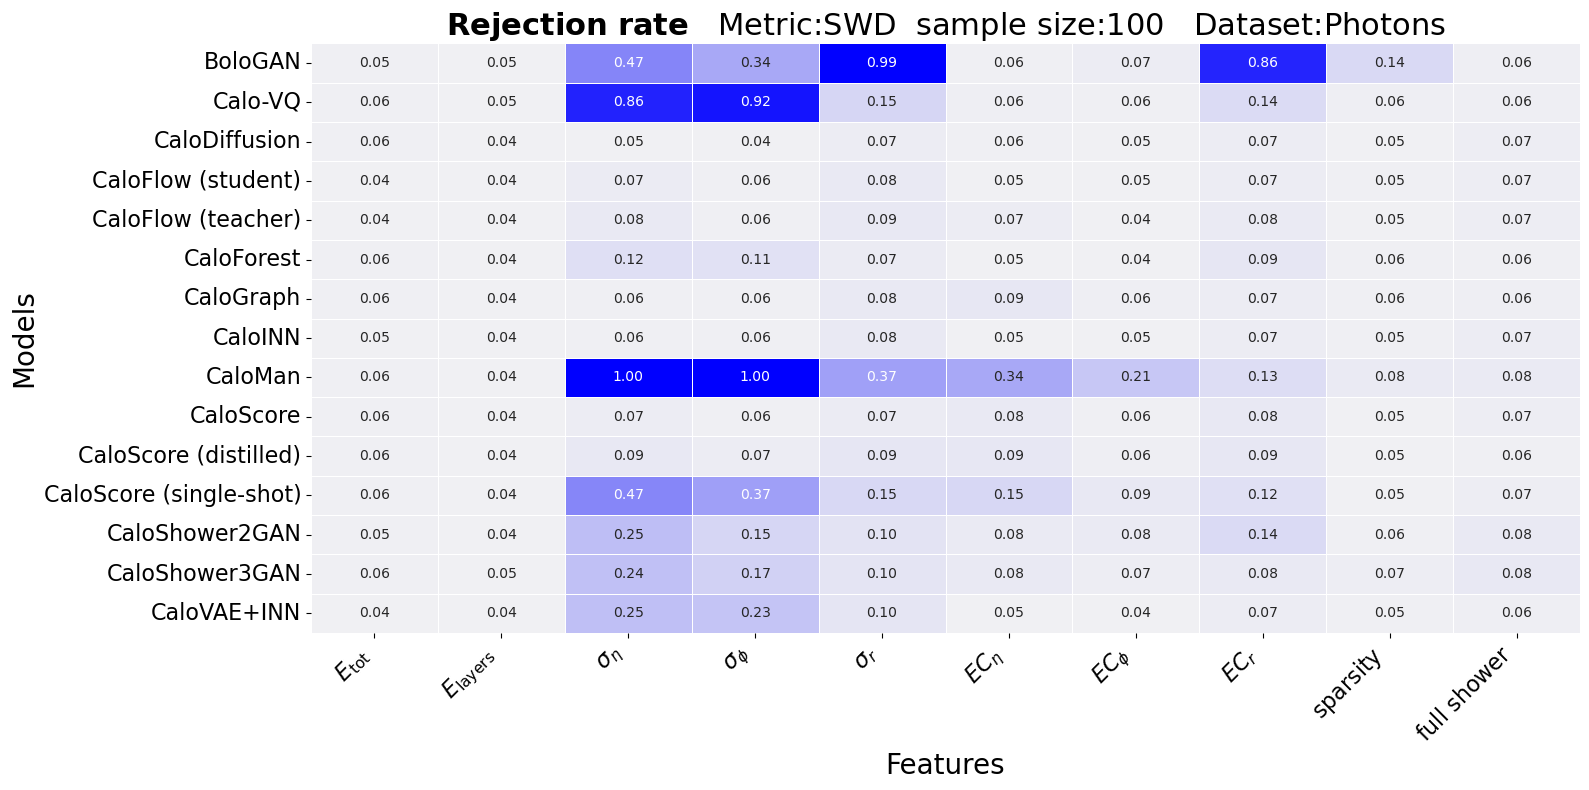

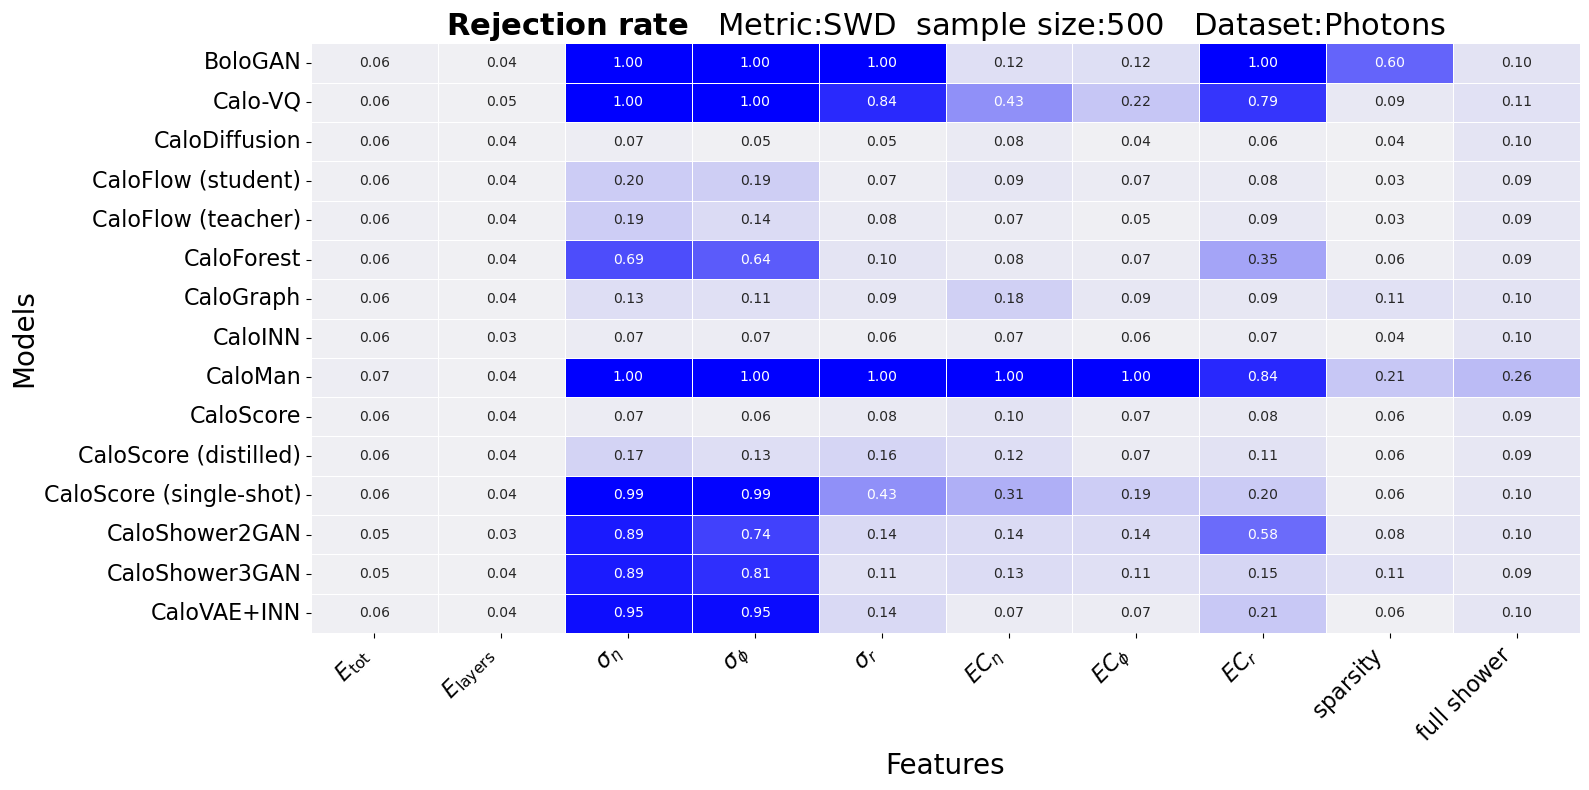

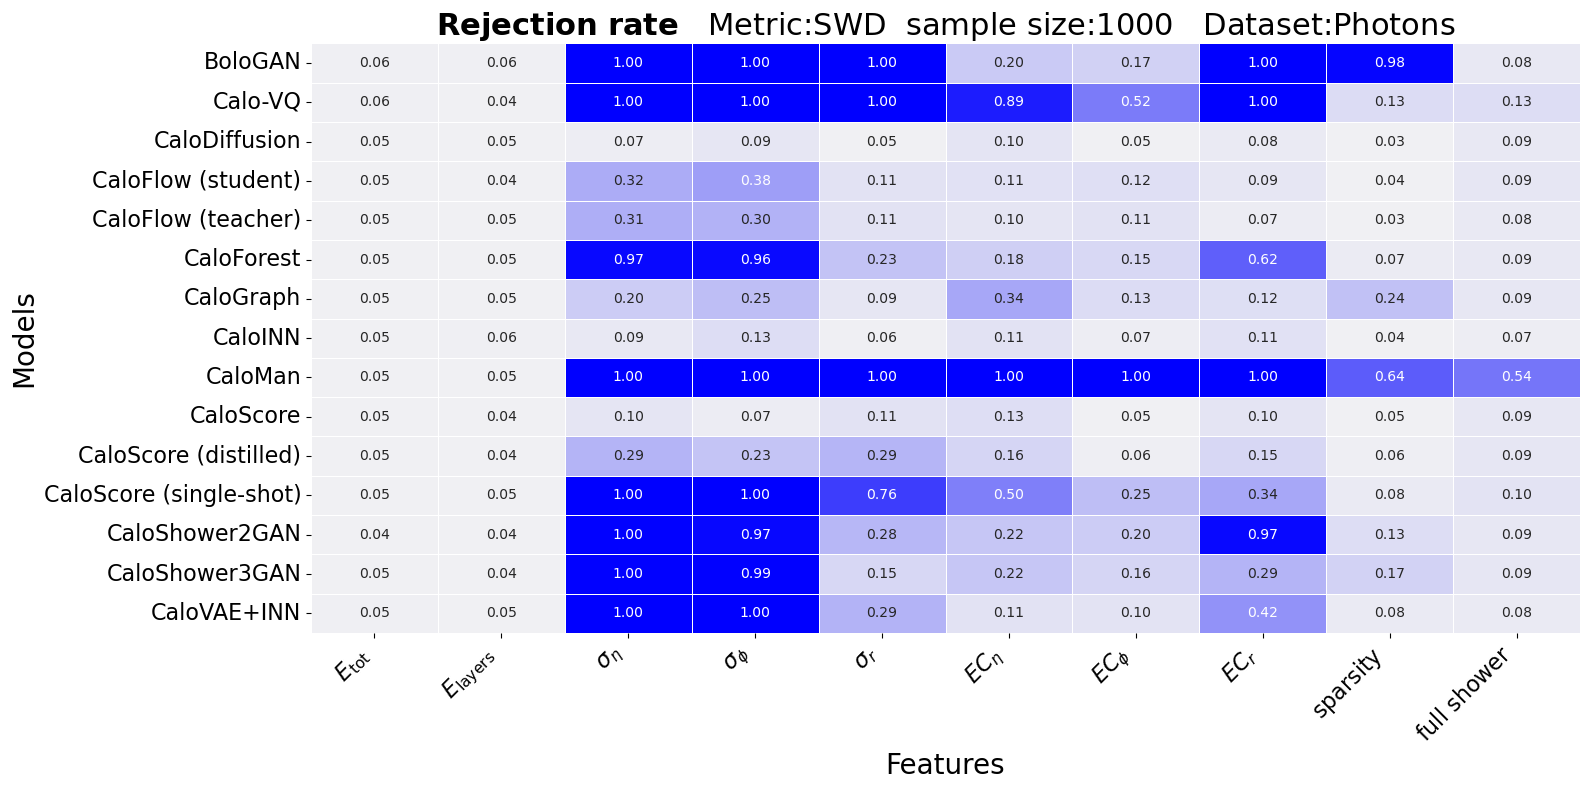

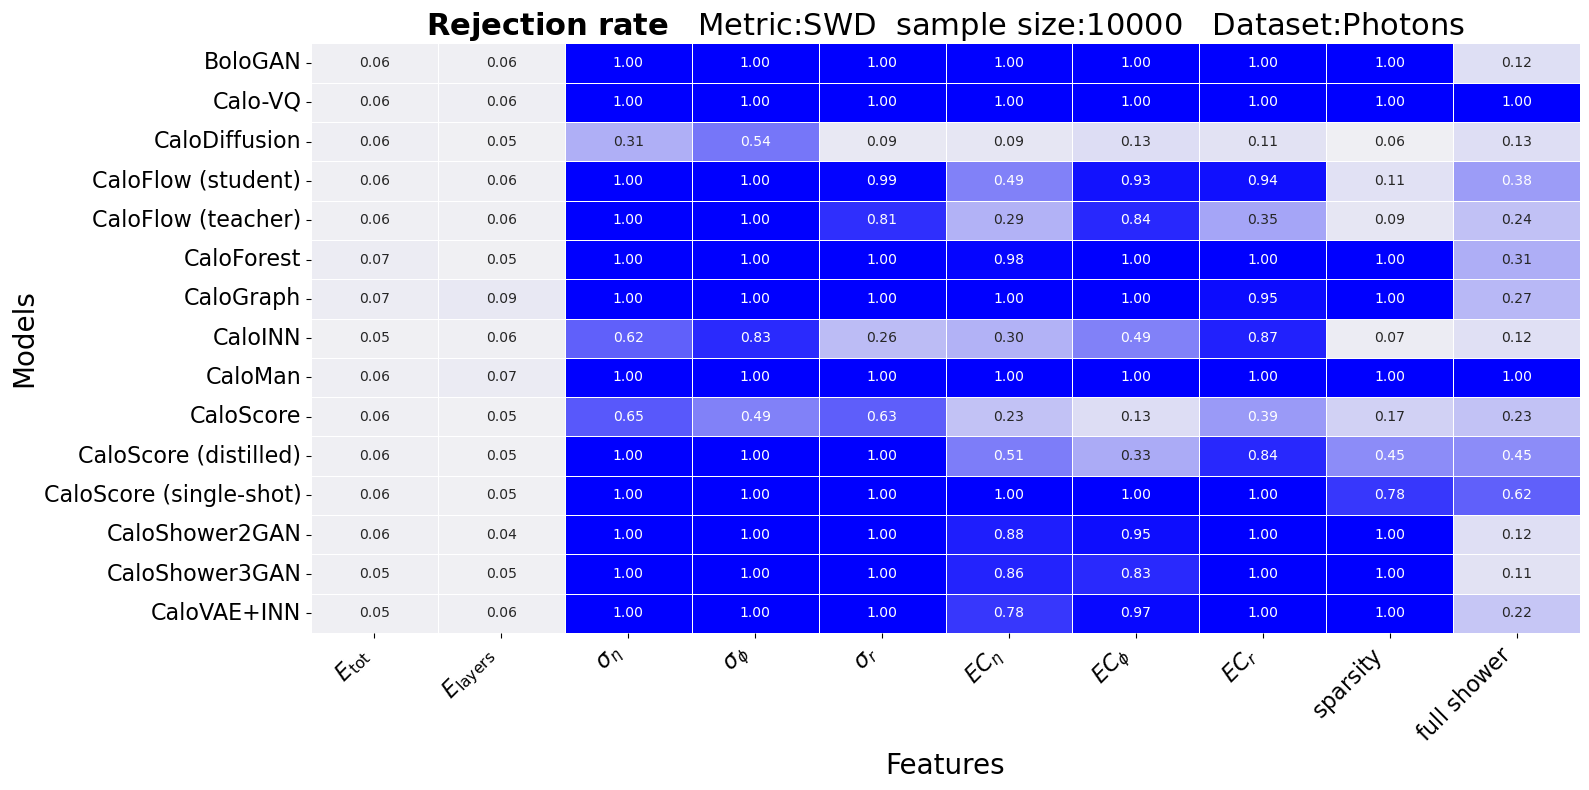

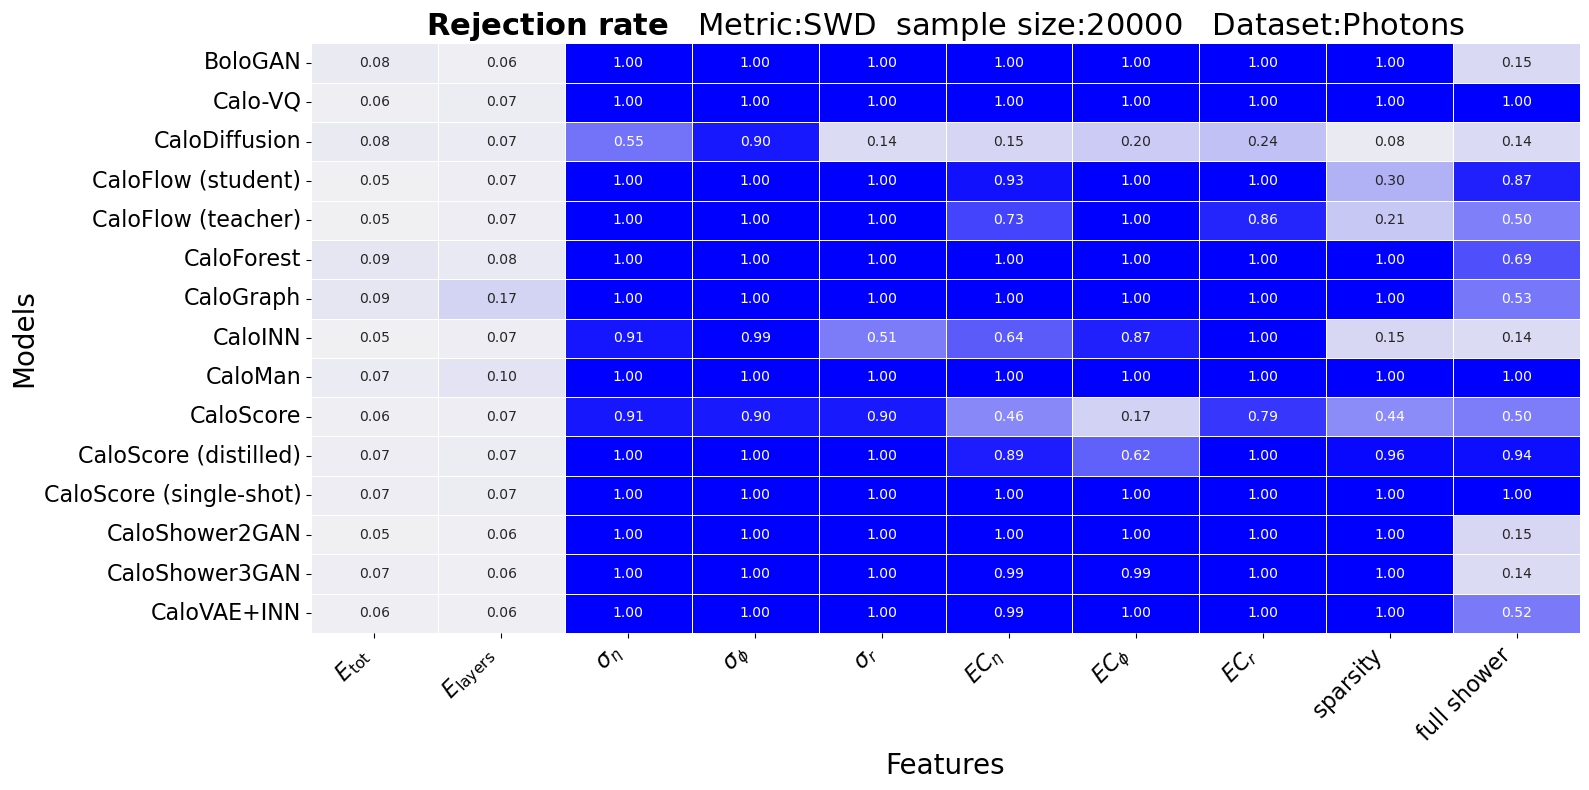

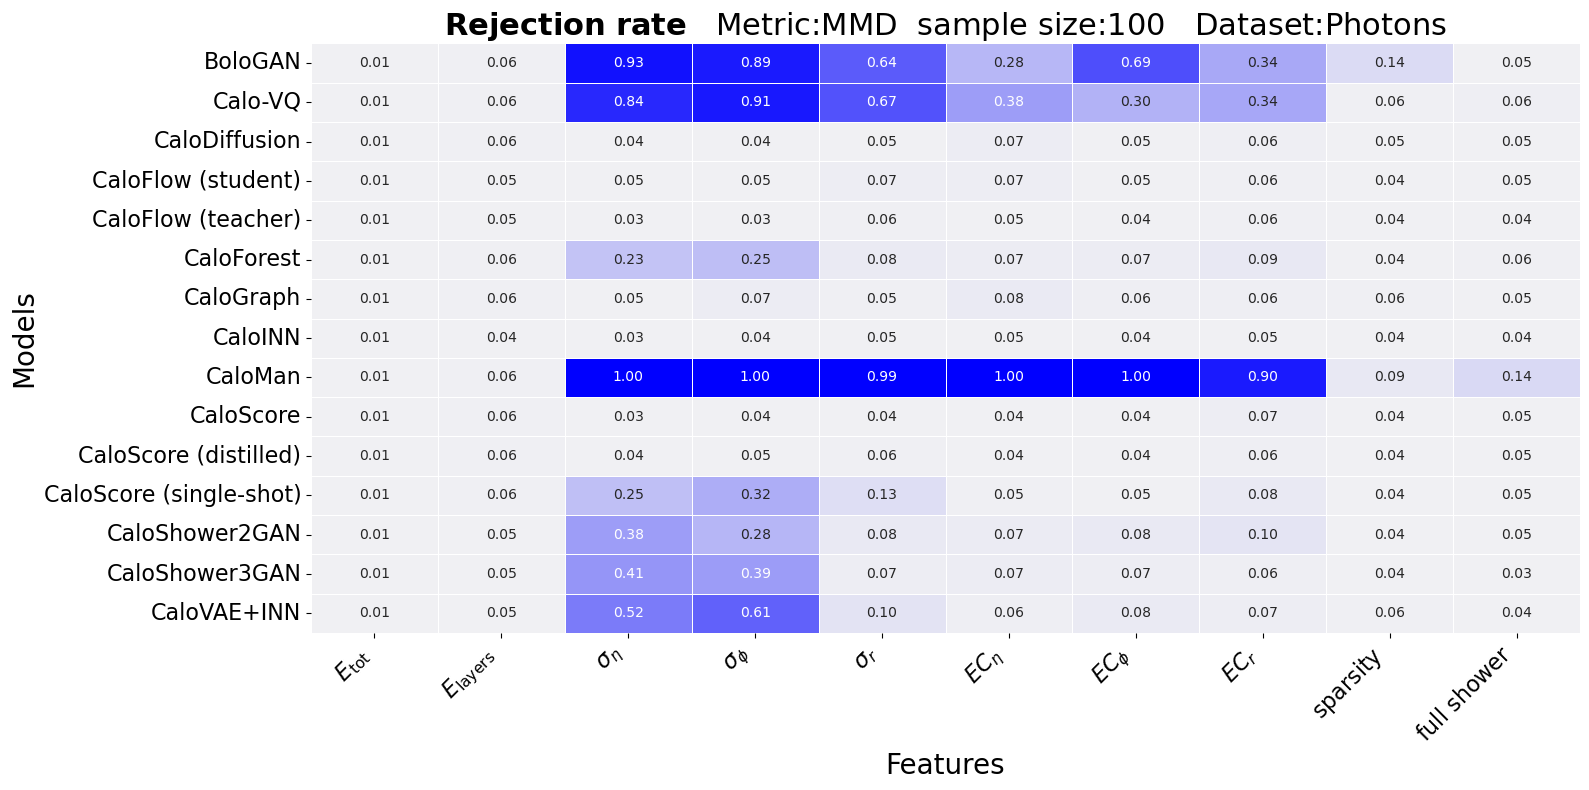

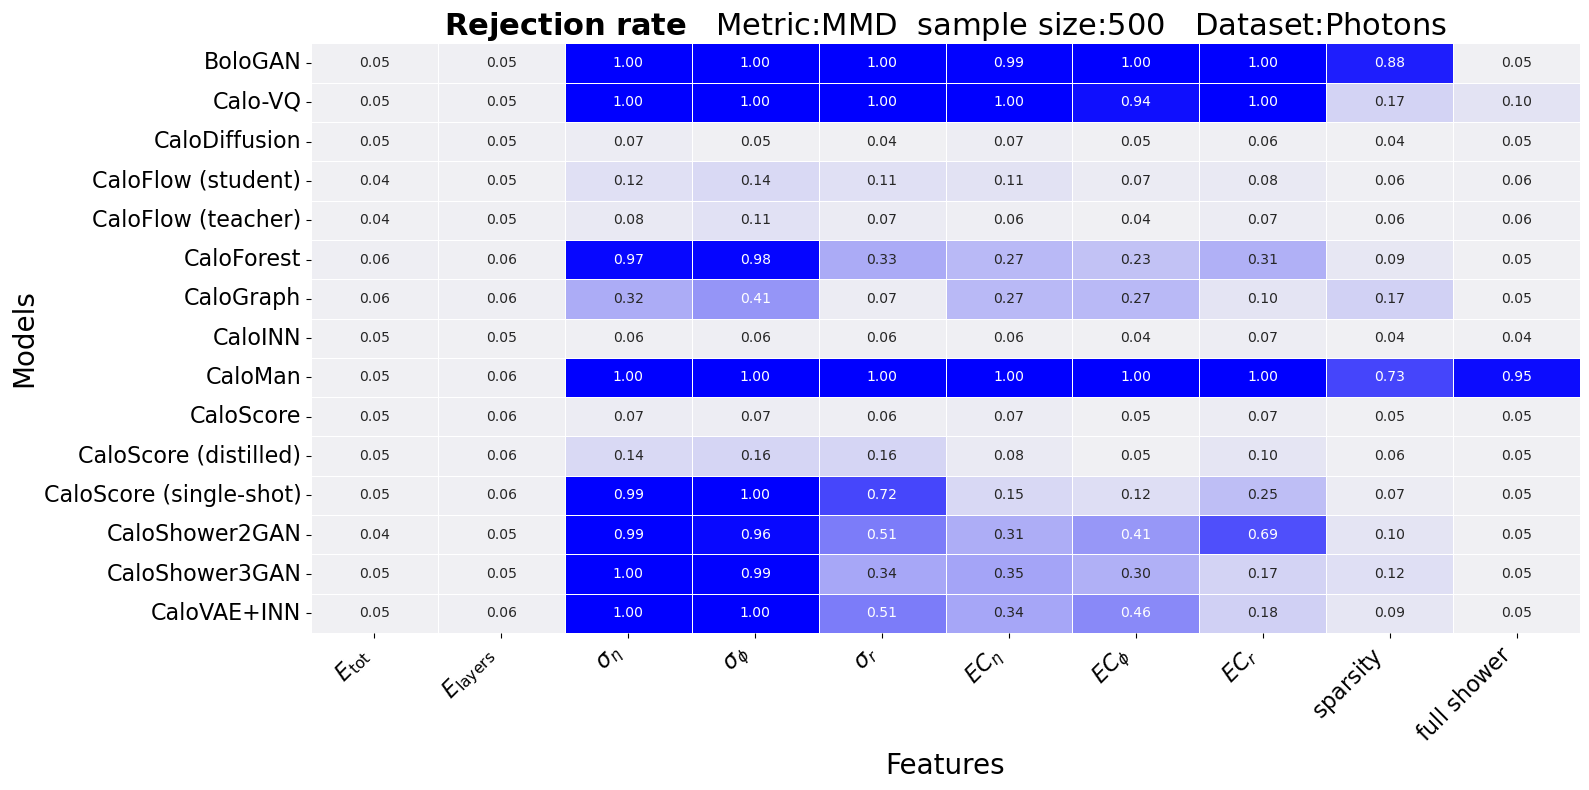

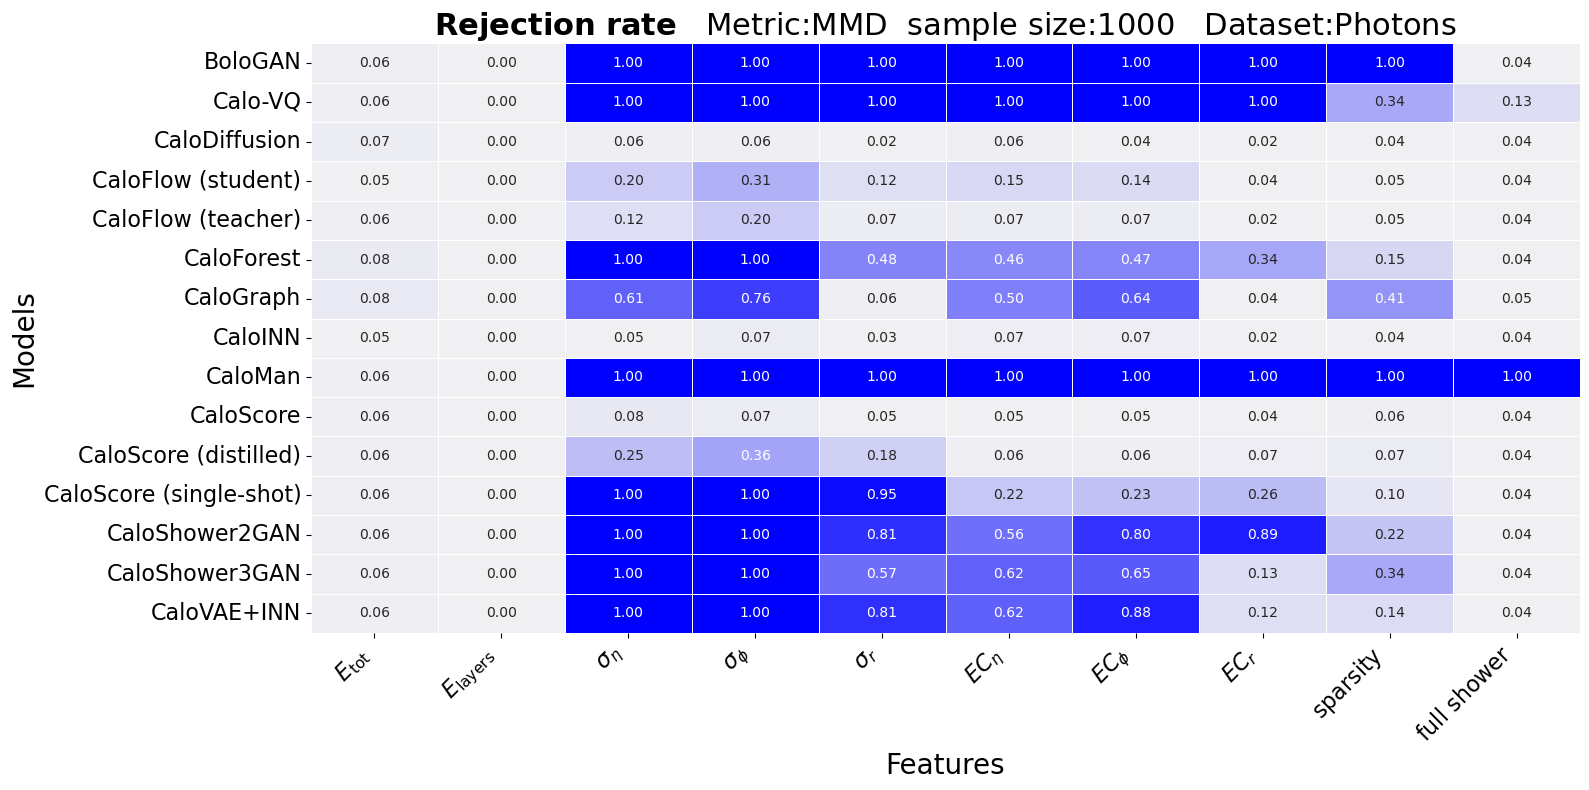

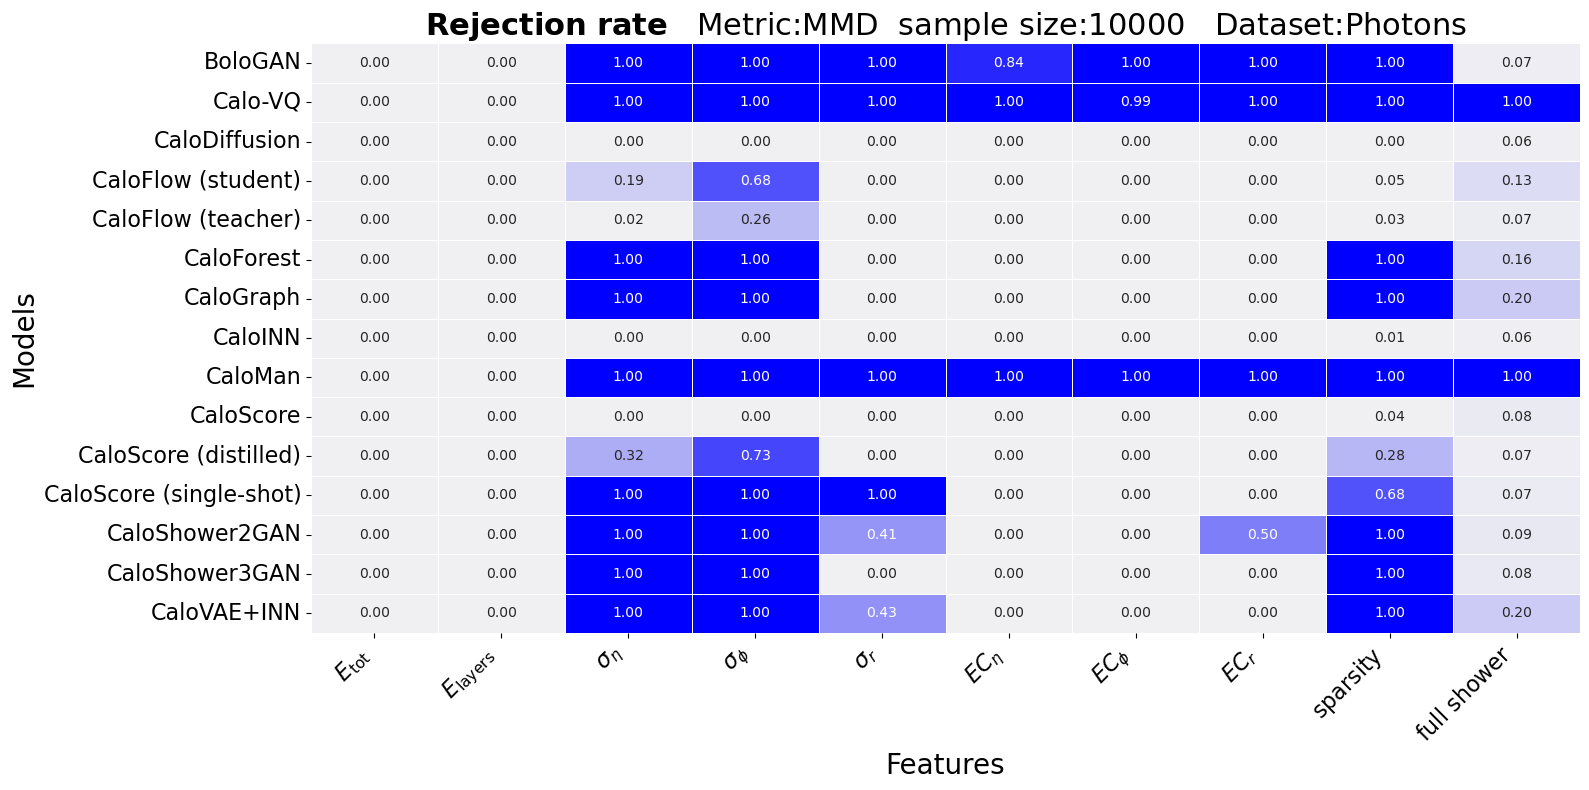

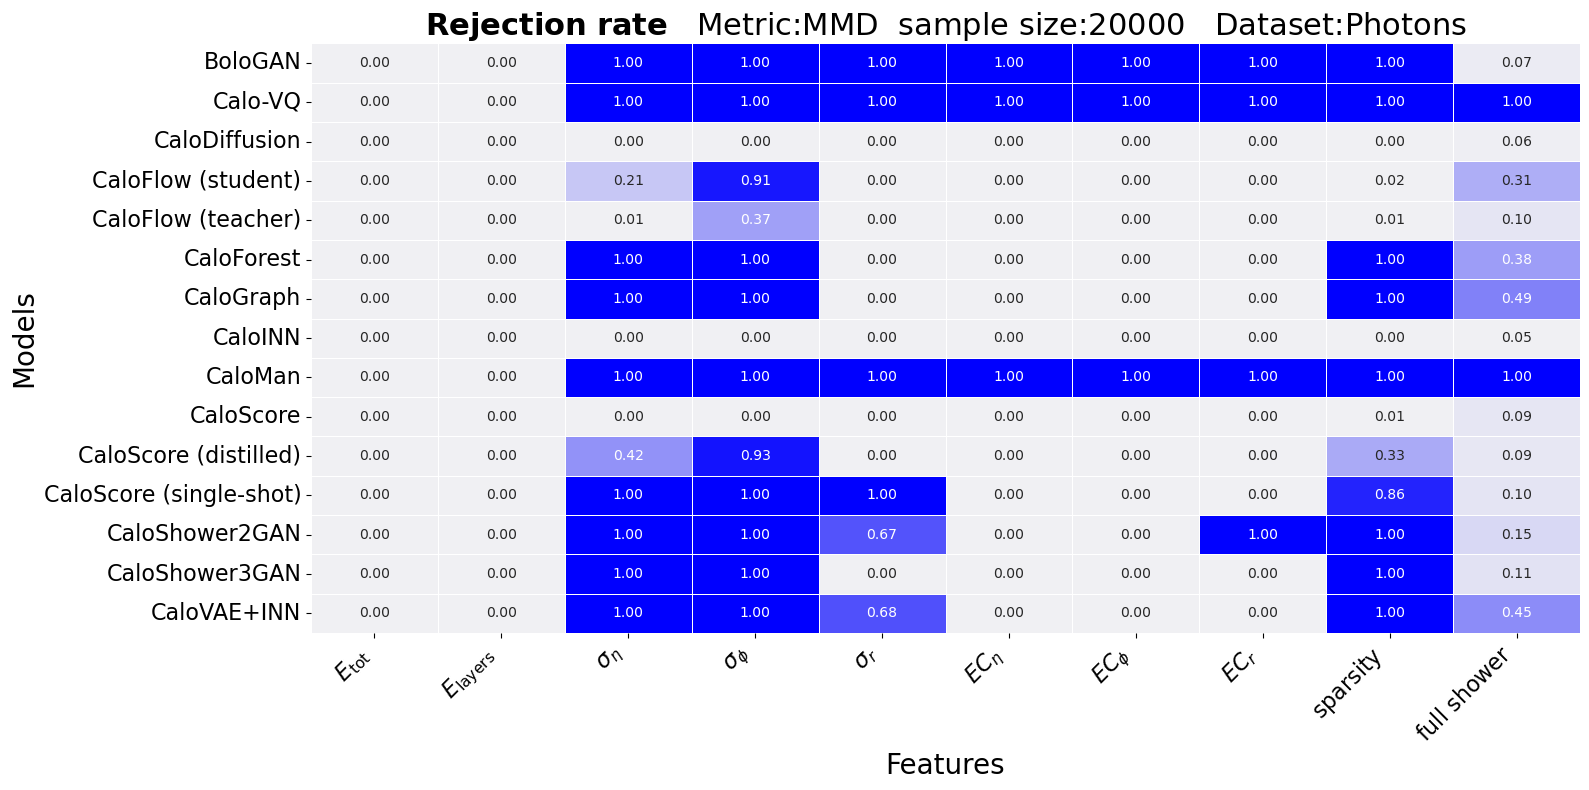

In [32]:
# 1. Compute the unified power dataframe once
import sys
df_power = compute_power_dataframe(alternative_df, null_df, alpha=0.05)

# 2. Generate heatmaps for specific slices
#plot_power_heatmap(df_power, target_metric='SWD', target_batch_size=10000)
tests: list = ["KS","SKS","SWD","MMD"]
batches: list = [100, 500, 1000, 10000, 20000]
for test in tests:
    output_dir: str = "/teo_fs_fast/projects/GENOVA/figures/"+"ds_"+str(dataset)+"_"+test
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    for batch in batches:
        fname: str= "ds_"+str(dataset)+"_"+test+"_stat_"+str(batch)
        plot_power_heatmap(df_power, target_metric=test, target_batch_size=batch)
        plt.savefig(output_dir+"/"+fname+".pdf", format= "pdf")
    